# Fix Before You Recognize: diabetic-retinopathy case study (runs in any Jupyter, resumable)

Run the cells top to bottom. Everything is checkpointed under `DR_ROOT` (default `./dr_work`), so after a disconnect or kernel restart you simply **re-run from the top**: finished work is skipped.

| Stage | What gets cached | On re-run |
|---|---|---|
| Datasets | kagglehub cache | not re-downloaded |
| Master images + manifest | `cache/master/*.png`, `cache/manifest*.csv` | existing PNGs skipped |
| Classifier training | `save/ckpt_last.pt` every epoch, `save/locked_model.pt/.json` | resumes from the last epoch; skipped if finished |
| Every degradation / restoration evaluation | `probs/<model>/<set>/<condition>.npy` | loaded from disk, not recomputed |

To retrain from scratch, delete `save/locked_model.*` and `save/ckpt_last.pt`. To start over completely, delete `DR_ROOT`.

## 1. Configuration

In [2]:
# CONFIG: paths, seed and hyper-parameters. Every output lives under DR_ROOT (cache/, save/, probs/; figures in save/figures).
# Env vars DR_ROOT / APTOS_DIR / IDRID_DIR override the defaults. POLICY_HOLDOUT_FRAC keeps part of APTOS-train away from the classifier.
import os, sys, json, glob, io, re, time, pickle, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

ROOT = Path(os.environ.get('DR_ROOT', './dr_work')).resolve()          # all outputs live here
CACHE, SAVE, PROBS = ROOT / 'cache', ROOT / 'save', ROOT / 'probs'
for p in (CACHE, SAVE, PROBS): p.mkdir(parents=True, exist_ok=True)
FIG = SAVE / 'figures'; FIG.mkdir(exist_ok=True)                          # figures (same definition as in the final-report cell)
os.environ['DR_REF_PATH'] = str(SAVE / 'ref_cdf.npy')                   # read by dr_ops (also in worker processes)
if os.getcwd() not in sys.path: sys.path.insert(0, os.getcwd())         # dr_common.py / dr_ops.py are written next to the notebook

APTOS_DIR = os.environ.get('APTOS_DIR', '')     # set to an existing folder to skip the Kaggle download
IDRID_DIR = os.environ.get('IDRID_DIR', '')

REFERABLE_GRADE = 2          # label = DR grade >= 2 (referable DR); 1 = any DR
POLICY_HOLDOUT_FRAC = 0.35   # share of APTOS-train kept AWAY from the classifier, for developing the restoration policy.
                             # 0 reproduces the earlier setup (classifier trains on all of APTOS-train).
SEED = 0
EPOCHS, BS, LR = 15, 16, 3e-4
WORKERS = min(8, os.cpu_count() or 2)
print('work dir:', ROOT)

work dir: C:\Users\User\Downloads\dr_work


## 2. Packages (run once, then comment out)

In [3]:
# Imports + device selection (CUDA > Apple MPS > CPU). Mixed precision is used on CUDA only.
# %pip install -q torch torchvision timm kagglehub opencv-python-headless scikit-learn scikit-image PyWavelets pandas matplotlib pillow
import cv2, torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
if torch.cuda.is_available(): dev = 'cuda'
elif getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available(): dev = 'mps'
else: dev = 'cpu'
use_amp = dev == 'cuda'
torch.manual_seed(SEED); np.random.seed(SEED)
print(torch.__version__, '| device:', dev, '| workers:', WORKERS)

2.11.0+cu128 | device: cuda | workers: 8


## 3. Download both Kaggle datasets
If it asks for credentials, run `kagglehub.login()` first (Kaggle account + API token).

In [5]:
# Download APTOS-2019 and IDRiD through kagglehub (cached after the first run).
import kagglehub
APTOS = APTOS_DIR or kagglehub.dataset_download('mariaherrerot/aptos2019')
IDRID = IDRID_DIR or kagglehub.dataset_download('mariaherrerot/idrid-dataset')
print(APTOS); print(IDRID)

C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\idrid-dataset\versions\1


## 4. Inspect layout

In [6]:
# Print folder / CSV layout of both datasets so the SOURCES table in section 6 can be checked against the real file names.
IMGEXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff')
def inspect(root, maxdepth=3):
    for dp, dn, fn in os.walk(root):
        if dp[len(root):].count(os.sep) > maxdepth: continue
        imgs = [f for f in fn if f.lower().endswith(IMGEXT)]
        other = [f for f in fn if not f.lower().endswith(IMGEXT)]
        print(f"{dp}  [{len(imgs)} images] e.g. {imgs[:2]} other={other[:8]}")
    for dp, _, fn in os.walk(root):
        for f in fn:
            if f.lower().endswith('.csv'):
                p = os.path.join(dp, f); df = pd.read_csv(p)
                print(f"\n=== {p} shape={df.shape}"); print(df.head(3).to_string())
                for c in df.columns:
                    if df[c].nunique() <= 6: print(f"  counts[{c}]:", df[c].value_counts().to_dict())
for r in (APTOS, IDRID):
    print('#' * 20, r); inspect(str(r)); print()

#################### C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3  [0 images] e.g. [] other=['test.csv', 'train_1.csv', 'valid.csv']
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\test_images  [0 images] e.g. [] other=[]
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\test_images\test_images  [366 images] e.g. ['e4dcca36ceb4.png', 'e4e343eaae2a.png'] other=[]
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\train_images  [0 images] e.g. [] other=[]
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\train_images\train_images  [2930 images] e.g. ['1ae8c165fd53.png', '1b329a127307.png'] other=[]
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\val_images  [0 images] e.g. [] other=[]
C:\Users\User\.cache\kagglehub\datasets\mariaherrerot\aptos2019\versions\3\

## 5. Shared modules
Written as real `.py` files (next to the notebook) so DataLoader worker processes can import them on any OS. `dr_common.py` = the locked pipeline; `dr_ops.py` = degradations, restorers and the picklable `SpecFn`.

In [7]:
%%writefile dr_common.py
# LOCKED pipeline = locked_preprocess + model + threshold.
# Degradation / restoration plug in via `raw_transform` (a picklable callable acting on the
# full master RGB image BEFORE the locked preprocessing).
import cv2, numpy as np, torch, timm
from torch.utils.data import Dataset
from sklearn.metrics import roc_auc_score, roc_curve

MASTER_SIZE = 1024      # cached clean master images (square, black-border cropped)
IMG_SIZE = 512          # input size of the locked classifier
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)


def crop_square(rgb, size=MASTER_SIZE, thresh=10):
    mask = rgb.mean(axis=2) > thresh
    if mask.sum() > 100:
        ys, xs = np.where(mask)
        rgb = rgb[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = rgb.shape[:2]; s = max(h, w)
    canvas = np.zeros((s, s, 3), np.uint8)
    canvas[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = rgb
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)


def locked_preprocess(rgb):
    x = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    x = (x.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())


class DRDataset(Dataset):
    def __init__(self, df, augment=False, raw_transform=None):
        self.df = df.reset_index(drop=True); self.augment = augment; self.raw_transform = raw_transform

    def __len__(self): return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        rgb = cv2.cvtColor(cv2.imread(r['master_path']), cv2.COLOR_BGR2RGB)
        if self.raw_transform is not None: rgb = self.raw_transform(rgb)
        x = locked_preprocess(rgb)
        if self.augment:   # geometric only, on purpose: photometric aug would pre-train robustness
            if np.random.rand() < 0.5: x = torch.flip(x, [2])
            if np.random.rand() < 0.5: x = torch.flip(x, [1])
            x = torch.rot90(x, np.random.randint(4), [1, 2])
        return x, torch.tensor(float(r['label'])), i


def build_model(pretrained=True):
    return timm.create_model('efficientnet_b0', pretrained=pretrained, num_classes=1)


@torch.no_grad()
def predict(model, loader, device):
    model.eval(); out = []
    for x, _, _ in loader:
        out.append(torch.sigmoid(model(x.to(device)).squeeze(1)).float().cpu())
    return torch.cat(out).numpy()


def pick_threshold(y, p, min_sens=0.90):
    fpr, tpr, thr = roc_curve(y, p)
    ok = np.where(tpr >= min_sens)[0]
    return float(thr[ok[np.argmin(fpr[ok])]])


def metrics(y, p, thr):
    y = np.asarray(y); pred = p >= thr
    tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    tn = ((pred == 0) & (y == 0)).sum(); fp = ((pred == 1) & (y == 0)).sum()
    return dict(n=len(y), auc=roc_auc_score(y, p), acc=(pred == y).mean(),
                sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1))

Overwriting dr_common.py


In [8]:
%%writefile dr_ops.py
# Degradation (DEG) and restoration (RES) operations + picklable SpecFn.
# Degradation spec : list of (name, kwargs) applied in order, e.g. [('gauss_noise', {'sigma': 8}), ('jpeg', {'q': 50})]
# Restoration chain: list of (name, kwargs) applied in order after the degradation.
# Specs are plain data (JSON-able), so they can serve as RL actions and survive multiprocessing 'spawn'.
import io, os, functools
import numpy as np, cv2
from PIL import Image

DEG, RES = {}, {}
def deg(name):
    def d(f): DEG[name] = f; return f
    return d
def res(name):
    def d(f): RES[name] = f; return f
    return d

def _clip(x): return np.clip(x, 0, 255).astype(np.uint8)
def _grid(h, w):
    yy, xx = np.mgrid[:h, :w].astype(np.float32)
    return (yy - h / 2) / (h / 2), (xx - w / 2) / (w / 2)

# ============================ degradations: f(x, rng, **kw) ============================
@deg('gauss_blur')
def d_gauss_blur(x, rng, sigma): return cv2.GaussianBlur(x, (0, 0), sigma)
@deg('defocus')
def d_defocus(x, rng, radius):
    k = np.zeros((2 * radius + 1,) * 2, np.float32); cv2.circle(k, (radius, radius), radius, 1, -1)
    return cv2.filter2D(x, -1, k / k.sum())
@deg('motion')
def d_motion(x, rng, length):
    k = np.zeros((length, length), np.float32); cv2.line(k, (0, length // 2), (length - 1, length // 2), 1, 1)
    M = cv2.getRotationMatrix2D((length / 2 - 0.5, length / 2 - 0.5), rng.uniform(0, 180), 1)
    k = cv2.warpAffine(k, M, (length, length))
    return cv2.filter2D(x, -1, k / max(k.sum(), 1e-6))

@deg('gauss_noise')
def d_gauss_noise(x, rng, sigma): return _clip(x + rng.normal(0, sigma, x.shape))
@deg('pg_noise')
def d_pg_noise(x, rng, gain, read=2.0):          # shot noise (variance grows with brightness) + read noise
    return _clip(rng.poisson(np.clip(x.astype(np.float32), 0, 255) / gain) * gain + rng.normal(0, read, x.shape))
@deg('lowlight')
def d_lowlight(x, rng, dark, gain=1.0, read=2.0):  # underexposed capture, noise, then brightened
    d = x.astype(np.float32) * dark
    return _clip((rng.poisson(d / gain) * gain + rng.normal(0, read, x.shape)) / dark)
@deg('chroma_noise')
def d_chroma_noise(x, rng, sigma):                # colour-only noise
    y = cv2.cvtColor(x, cv2.COLOR_RGB2YCrCb).astype(np.float32)
    y[..., 1:] += rng.normal(0, sigma, y[..., 1:].shape)
    return cv2.cvtColor(_clip(y), cv2.COLOR_YCrCb2RGB)
@deg('saltpepper')
def d_saltpepper(x, rng, frac):                   # hot / dead pixels
    m = rng.random(x.shape[:2]); y = x.copy(); y[m < frac / 2] = 0; y[m > 1 - frac / 2] = 255; return y

@deg('jpeg')
def d_jpeg(x, rng, q, sub=2):                     # sub: 0 = 4:4:4, 2 = 4:2:0 chroma subsampling
    b = io.BytesIO(); Image.fromarray(x).save(b, 'JPEG', quality=int(q), subsampling=sub); b.seek(0)
    return np.array(Image.open(b).convert('RGB'))
@deg('resize')
def d_resize(x, rng, scale):
    h, w = x.shape[:2]; return cv2.resize(x, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
@deg('recompress')
def d_recompress(x, rng, rounds, q, scale=0.9):   # forwarded repeatedly: resize + JPEG each round
    for _ in range(rounds): x = d_jpeg(d_resize(x, rng, scale), rng, q)
    return x

@deg('vignette')
def d_vignette(x, rng, strength):
    yy, xx = _grid(*x.shape[:2]); r = np.minimum(np.hypot(yy, xx), 1)
    return _clip(x * (1 - strength * r ** 2)[..., None])
@deg('uneven')
def d_uneven(x, rng, strength):                   # one side brighter than the other
    yy, xx = _grid(*x.shape[:2]); a = rng.uniform(0, 2 * np.pi)
    return _clip(x * (1 + strength * (np.cos(a) * xx + np.sin(a) * yy) / 1.42)[..., None])
@deg('gamma')
def d_gamma(x, rng, g): return _clip(255 * (x / 255.0) ** g)      # g<1 brighter, g>1 darker
@deg('contrast')
def d_contrast(x, rng, c): m = x.mean(); return _clip((x - m) * c + m)
@deg('haze')
def d_haze(x, rng, t, A=210): return _clip(x * (1 - t) + A * t)
@deg('wb')
def d_wb(x, rng, r, g, b): return _clip(x * np.array([r, g, b], np.float32))
@deg('saturation')
def d_saturation(x, rng, s):
    h = cv2.cvtColor(x, cv2.COLOR_RGB2HSV).astype(np.float32); h[..., 1] *= s
    return cv2.cvtColor(_clip(h), cv2.COLOR_HSV2RGB)
@deg('posterize')
def d_posterize(x, rng, bits): s = 8 - bits; return (x >> s) << s

@deg('smooth')
def d_smooth(x, rng, passes):                     # aggressive phone "beauty"/denoise smoothing
    for _ in range(passes): x = cv2.bilateralFilter(x, 9, 40, 9)
    return x
@deg('oversharp')
def d_oversharp(x, rng, amt, s=2): return cv2.addWeighted(x, 1 + amt, cv2.GaussianBlur(x, (0, 0), s), -amt, 0)

@deg('glare')
def d_glare(x, rng, strength, radius=0.18):
    h, w = x.shape[:2]; cy, cx = rng.uniform(0.25, 0.75, 2) * np.array([h, w]); yy, xx = np.mgrid[:h, :w]
    g = np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * (radius * h) ** 2))
    return _clip(x + 255 * strength * g[..., None])
@deg('eyelid')
def d_eyelid(x, rng, frac):                       # soft dark band over top or bottom
    h = x.shape[0]; yy = np.arange(h, dtype=np.float32)[:, None]
    d = (frac * h - yy) if rng.random() < 0.5 else (yy - (1 - frac) * h)
    return _clip(x * (1 - np.clip(d / (0.03 * h) + 0.5, 0, 1))[:, :, None])
@deg('zoom')
def d_zoom(x, rng, z):                            # tight field of view (periphery lost)
    h, w = x.shape[:2]; ch, cw = int(h / z), int(w / z); y0, x0 = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(x[y0:y0 + ch, x0:x0 + cw], (w, h), interpolation=cv2.INTER_CUBIC)
@deg('shift')
def d_shift(x, rng, frac):                        # off-centre capture
    h, w = x.shape[:2]; a = rng.uniform(0, 2 * np.pi)
    return cv2.warpAffine(x, np.float32([[1, 0, frac * w * np.cos(a)], [0, 1, frac * h * np.sin(a)]]), (w, h))
@deg('rotate')
def d_rotate(x, rng, deg):                        # handheld tilt
    h, w = x.shape[:2]
    return cv2.warpAffine(x, cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-deg, deg), 1), (w, h))

# ============================ restoration: f(x, **kw), deterministic ============================
@functools.lru_cache(maxsize=8)
def _disc(h, w, r=0.42):
    yy, xx = np.mgrid[:h, :w]
    return ((yy - h / 2) ** 2 + (xx - w / 2) ** 2) < (r * min(h, w)) ** 2

def _cdf(ch, r=0.42):
    c = np.cumsum(np.bincount(ch[_disc(*ch.shape, r)], minlength=256)).astype(np.float64)
    return c / c[-1]

_REF = {}
def build_ref(paths, out):
    # reference colour distribution = mean per-channel CDF over CLEAN images (set DR_REF_PATH to `out`)
    acc = np.zeros((3, 256))
    for p in paths:
        im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        for c in range(3): acc[c] += _cdf(im[..., c])
    acc /= len(paths); np.save(out, acc); _REF.clear(); return acc
def ref():
    if 'cdf' not in _REF: _REF['cdf'] = np.load(os.environ['DR_REF_PATH'])
    return _REF['cdf']
def _ref_means():
    R = ref(); pmf = np.diff(np.concatenate([np.zeros((3, 1)), R], axis=1), axis=1)
    return (pmf * np.arange(256)).sum(1)

@res('nlm')
def r_nlm(x, h=10):
    return cv2.cvtColor(cv2.fastNlMeansDenoisingColored(cv2.cvtColor(x, cv2.COLOR_RGB2BGR), None, h, h, 7, 11), cv2.COLOR_BGR2RGB)
@res('gauss')
def r_gauss(x, sigma=1.0): return cv2.GaussianBlur(x, (0, 0), sigma)
@res('median')
def r_median(x, k=3): return cv2.medianBlur(x, k)
@res('bilateral')
def r_bilateral(x, sc=40): return cv2.bilateralFilter(x, 9, sc, 5)
@res('wavelet')
def r_wavelet(x, sigma=10):
    from skimage.restoration import denoise_wavelet
    out = denoise_wavelet(x.astype(np.float32) / 255, sigma=sigma / 255, channel_axis=-1, convert2ycbcr=True,
                          method='BayesShrink', mode='soft')
    return _clip(out * 255)
@res('unsharp')
def r_unsharp(x, amt=0.5, s=2): return cv2.addWeighted(x, 1 + amt, cv2.GaussianBlur(x, (0, 0), s), -amt, 0)
@res('wiener')
def r_wiener(x, sigma=2.0, balance=0.05):
    from skimage.restoration import wiener
    k = (int(6 * sigma) | 1); g = cv2.getGaussianKernel(k, sigma); psf = g @ g.T
    f = x.astype(np.float32) / 255
    return _clip(np.stack([wiener(f[..., c], psf, balance) for c in range(3)], -1) * 255)
@res('hist_match')
def r_hist_match(x, alpha=1.0):                   # map each channel's histogram to the clean-reference one
    R = ref(); out = np.empty_like(x)
    for c in range(3):
        lut = np.clip(np.searchsorted(R[c], _cdf(x[..., c])), 0, 255).astype(np.uint8)
        out[..., c] = lut[x[..., c]]
    return cv2.addWeighted(x, 1 - alpha, out, alpha, 0) if alpha < 1 else out
@res('clahe')
def r_clahe(x, clip=2.0, tile=8):
    lab = cv2.cvtColor(x, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
@res('gamma_auto')
def r_gamma_auto(x, strength=1.0):                # pick gamma so mean brightness matches the clean reference
    target = float(_ref_means().mean()) / 255
    cur = float(x[_disc(*x.shape[:2])].mean()) / 255
    if cur <= 1e-3 or cur >= 0.999: return x
    g = float(np.clip(np.log(target) / np.log(cur), 0.4, 2.5)) ** strength
    return _clip(255 * (x / 255.0) ** g)
@res('color_match')
def r_color_match(x, strength=1.0):               # per-channel gain so channel means match the clean reference
    cur = x[_disc(*x.shape[:2])].reshape(-1, 3).mean(0)
    gain = (_ref_means() / np.maximum(cur, 1.0)) ** strength
    return _clip(x * gain.astype(np.float32))
@res('dehaze')
def r_dehaze(x, omega=0.8, t0=0.15, patch=15):    # dark-channel-prior dehazing
    I = x.astype(np.float32) / 255; ker = np.ones((patch, patch), np.uint8)
    mk = _disc(*x.shape[:2])
    dark = cv2.erode(I.min(axis=2), ker)
    n = max(int(mk.sum() * 0.001), 1)
    idx = np.argpartition(np.where(mk, dark, -1).ravel(), -n)[-n:]
    A = I.reshape(-1, 3)[idx].mean(0)
    t = 1 - omega * cv2.erode((I / np.maximum(A, 1e-3)).min(axis=2), ker)
    t = cv2.GaussianBlur(np.clip(t, t0, 1), (0, 0), patch / 3)
    return _clip(((I - A) / t[..., None] + A) * 255)
@res('flatten')
def r_flatten(x, sigma=60, alpha=1.0):            # remove slow illumination gradients (masked single-scale retinex)
    f = x.astype(np.float32); mk = _disc(*x.shape[:2], 0.5); m3 = mk.astype(np.float32)[..., None]
    bg = cv2.GaussianBlur(f * m3, (0, 0), sigma) / (cv2.GaussianBlur(m3[..., 0], (0, 0), sigma)[..., None] + 1e-3)
    gm = (bg * m3).reshape(-1, 3).sum(0) / m3.sum()
    y = _clip(f / (bg + 1.0) * gm * m3)
    return cv2.addWeighted(x, 1 - alpha, y, alpha, 0) if alpha < 1 else y

# ============================ picklable transform ============================
class SpecFn:
    # callable: degrade (seeded by clean-image content, so reproducible) then restore
    def __init__(self, deg=None, chain=None):
        self.deg = [tuple(s) for s in (deg or [])]; self.chain = [tuple(s) for s in (chain or [])]
    def __call__(self, rgb):
        if self.deg:
            rng = np.random.default_rng(int(rgb[::97, ::97].sum()) % (2 ** 32))
            for name, kw in self.deg: rgb = DEG[name](rgb, rng, **kw)
        for name, kw in self.chain: rgb = RES[name](rgb, **kw)
        return rgb

Overwriting dr_ops.py


In [9]:
# Reload the shared modules so edits to dr_common.py / dr_ops.py take effect without restarting the kernel.
import importlib, dr_common, dr_ops
importlib.reload(dr_common); importlib.reload(dr_ops)
from dr_common import *
from dr_ops import SpecFn
print('modules loaded')

modules loaded


## 6. Build manifest + cache clean master images (resumable)
Label = grade >= `REFERABLE_GRADE`. Images are found by file stem anywhere under each dataset root.

In [10]:
# Build the master manifest: match each CSV row to an image, crop the black border, pad to square, resize to 1024 px, cache as PNG.
# Label = DR grade >= REFERABLE_GRADE (referable DR). IDRiD is used only as an external test set.
from multiprocessing.pool import ThreadPool

IDRID_CSV = f'{IDRID}/idrid_labels.csv'
# (dataset, split, csv_path, image_root, id_column, grade_column)
SOURCES = [
    ('aptos', 'train', f'{APTOS}/train_1.csv', APTOS, 'id_code', 'diagnosis'),
    ('aptos', 'val',   f'{APTOS}/valid.csv',   APTOS, 'id_code', 'diagnosis'),
    ('aptos', 'test',  f'{APTOS}/test.csv',    APTOS, 'id_code', 'diagnosis'),
    ('idrid', 'test',  IDRID_CSV,              IDRID, 'id_code', 'diagnosis'),   # all IDRiD = external set
]

def index_images(root):
    return {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(os.path.join(str(root), '**', '*'), recursive=True)
            if p.lower().endswith(IMGEXT)}

def cache_one(a):
    src, dst = a
    if not os.path.exists(dst):                      # resumable: skip finished images
        rgb = cv2.cvtColor(cv2.imread(src), cv2.COLOR_BGR2RGB)
        cv2.imwrite(dst, cv2.cvtColor(crop_square(rgb), cv2.COLOR_RGB2BGR))

rows, jobs, idx_cache = [], [], {}
for ds, split, csv, root, idc, gc in SOURCES:
    if not os.path.exists(csv): print('SKIP (csv not found):', csv); continue
    idx_cache.setdefault(root, index_images(root))
    df = pd.read_csv(csv).dropna(subset=[idc, gc])
    (CACHE / 'master' / ds).mkdir(parents=True, exist_ok=True); miss = []
    for _, r in df.iterrows():
        stem = os.path.splitext(str(r[idc]).strip())[0]
        found = stem if stem in idx_cache[root] else (stem + 'test' if stem + 'test' in idx_cache[root] else None)
        if found is None: miss.append(stem); continue
        dst = str(CACHE / 'master' / ds / f'{found}.png'); jobs.append((idx_cache[root][found], dst))
        rows.append(dict(dataset=ds, split=split, id=found, grade=int(r[gc]),
                         label=int(r[gc] >= REFERABLE_GRADE), master_path=dst))
    print(f'{ds}/{split}: {len(df)} rows, {len(miss)} images not found', miss[:5])

manifest = pd.DataFrame(rows).drop_duplicates(['dataset', 'id'])
assert len(manifest) > 0, 'No images matched: check SOURCES against the output of section 4'
todo = [j for j in jobs if not os.path.exists(j[1])]; print(f'{len(todo)} of {len(jobs)} images still to cache')
with ThreadPool(os.cpu_count() * 2) as pool:
    for i, _ in enumerate(pool.imap_unordered(cache_one, todo, chunksize=8)):
        if i % 500 == 0: print('cached', i, '/', len(todo), flush=True)
manifest.to_csv(CACHE / 'manifest_raw.csv', index=False)
print(manifest.groupby(['dataset', 'split']).agg(n=('label', 'size'), pos_rate=('label', 'mean')).round(3))

aptos/train: 2930 rows, 0 images not found []
aptos/val: 366 rows, 0 images not found []
aptos/test: 366 rows, 0 images not found []
idrid/test: 455 rows, 0 images not found []
0 of 4117 images still to cache
                  n  pos_rate
dataset split                
aptos   test    366     0.374
        train  2930     0.408
        val     366     0.421
idrid   test    455     0.668


## 7. Splits + sanity check
`POLICY_HOLDOUT_FRAC` of APTOS-train becomes split `policy`: images the classifier **never trains on**. A classifier scores images it memorised more confidently, so a restoration policy developed on training images would see unrealistically easy cases.

                   n  pos_rate
dataset split                 
aptos   policy  1026     0.408
        test     366     0.374
        train   1904     0.408
        val      366     0.421
idrid   test     455     0.668


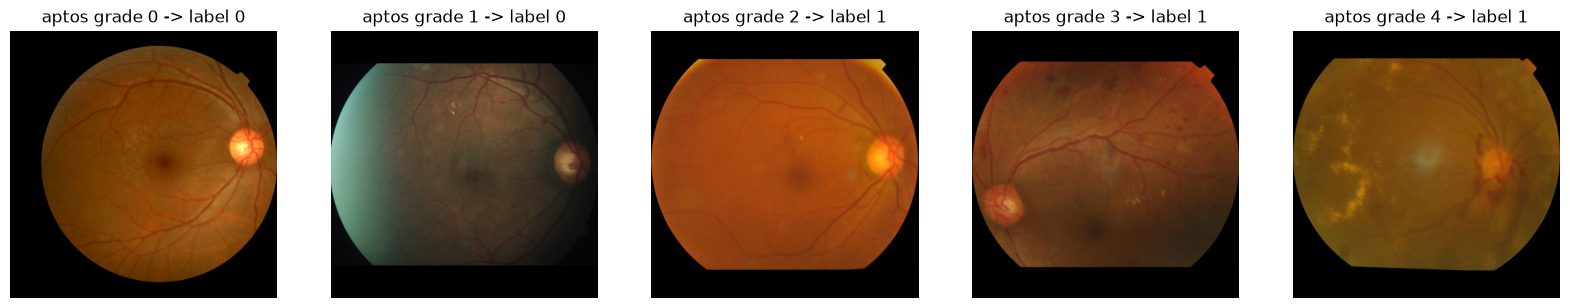

In [11]:
# Carve out split 'policy' (stratified by grade): images the classifier never trains on. The restoration policy is developed on these,
# because a classifier is over-confident on images it memorised.
from sklearn.model_selection import train_test_split
m = pd.read_csv(CACHE / 'manifest_raw.csv')
if POLICY_HOLDOUT_FRAC > 0:
    idx = m[(m.dataset == 'aptos') & (m.split == 'train')].index
    _, hold = train_test_split(idx, test_size=POLICY_HOLDOUT_FRAC, stratify=m.loc[idx, 'grade'], random_state=SEED)
    m.loc[hold, 'split'] = 'policy'
m.to_csv(CACHE / 'manifest.csv', index=False)
print(m.groupby(['dataset', 'split']).agg(n=('label', 'size'), pos_rate=('label', 'mean')).round(3))

s = m.groupby('grade').head(1).sort_values('grade').head(5)
fig, ax = plt.subplots(1, len(s), figsize=(4 * len(s), 4))
for a, (_, r) in zip(np.atleast_1d(ax), s.iterrows()):
    a.imshow(cv2.cvtColor(cv2.imread(r.master_path), cv2.COLOR_BGR2RGB))
    a.set_title(f'{r.dataset} grade {r.grade} -> label {r.label}'); a.axis('off')
plt.show()

## 8. Train the clean-image classifier (resumable: checkpoint every epoch)

In [12]:
# Train the clean-image classifier: EfficientNet-B0, pos-weighted BCE, AdamW + OneCycle, geometric augmentation only
# (photometric augmentation would pre-train robustness and hide the effect we study). Checkpoint every epoch -> resumable;
# the best val-AUC weights become locked_model.pt.
tr  = m[(m.dataset == 'aptos') & (m.split == 'train')]
va  = m[(m.dataset == 'aptos') & (m.split == 'val')]
pol = m[(m.dataset == 'aptos') & (m.split == 'policy')]
tests = {'aptos_val': va, 'aptos_test': m[(m.dataset == 'aptos') & (m.split == 'test')], 'idrid': m[m.dataset == 'idrid']}
if len(pol): tests['aptos_policy'] = pol
mk = lambda d, aug, sh: DataLoader(DRDataset(d, augment=aug), batch_size=BS, shuffle=sh,
                                   num_workers=WORKERS, pin_memory=(dev == 'cuda'))

LOCK_PT, LOCK_JSON, CKPT = SAVE / 'locked_model.pt', SAVE / 'locked_model.json', SAVE / 'ckpt_last.pt'
cfg_now = dict(holdout=POLICY_HOLDOUT_FRAC, seed=SEED, referable=REFERABLE_GRADE, n_train=int(len(tr)), epochs=EPOCHS)
locked_ok = LOCK_PT.exists() and LOCK_JSON.exists() and json.load(open(LOCK_JSON)).get('cfg') == cfg_now

if locked_ok:
    print('Locked model with this configuration already exists -> training skipped.')
else:
    tr_dl, va_dl = mk(tr, True, True), mk(va, False, False)
    net = build_model().to(dev)
    pos_w = torch.tensor((1 - tr.label.mean()) / tr.label.mean(), dtype=torch.float32).to(dev)
    crit = torch.nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(tr_dl))
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    start_ep, best = 0, 0.0
    if CKPT.exists():
        ck = torch.load(CKPT, map_location=dev)
        if ck.get('cfg') == cfg_now:
            net.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            scaler.load_state_dict(ck['scaler']); start_ep, best = ck['epoch'], ck['best']
            print(f'resuming from epoch {start_ep} (best val AUC so far {best:.4f})')
    for ep in range(start_ep, EPOCHS):
        t0 = time.time(); net.train(); tot = 0
        for x, y, _ in tr_dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast(device_type='cuda' if dev == 'cuda' else 'cpu', enabled=use_amp):
                loss = crit(net(x).squeeze(1), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y)
        auc = roc_auc_score(va.label, predict(net, va_dl, dev))
        if auc > best: best = auc; torch.save(net.state_dict(), LOCK_PT)
        torch.save(dict(model=net.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                        epoch=ep + 1, best=best, cfg=cfg_now), CKPT)
        print(f'epoch {ep+1:2d}  loss {tot/len(tr):.4f}  val AUC {auc:.4f}  ({time.time()-t0:.0f}s)', flush=True)
    print('best val AUC', round(best, 4))

Locked model with this configuration already exists -> training skipped.


## 9. Lock the model (threshold from val: highest specificity with sensitivity >= 90%) and evaluate on all clean sets

In [13]:
# Lock the classifier: threshold = highest specificity with sensitivity >= 90% on APTOS-val. Report clean metrics on every set.
model = build_model(pretrained=False).to(dev)
model.load_state_dict(torch.load(LOCK_PT, map_location=dev)); model.eval()
thr = pick_threshold(va.label.values, predict(model, mk(va, False, False), dev), min_sens=0.90)
json.dump(dict(threshold=thr, img_size=IMG_SIZE, arch='efficientnet_b0', label=f'grade>={REFERABLE_GRADE}', cfg=cfg_now),
          open(LOCK_JSON, 'w'))
print('locked threshold:', round(thr, 4))
res = {n: metrics(d.label.values, predict(model, mk(d, False, False), dev), thr) for n, d in tests.items() if len(d)}
clean_table = pd.DataFrame(res).T.round(3); clean_table.to_csv(SAVE / 'clean_results.csv')
clean_table

locked threshold: 0.9101


,n,auc,acc,sens,spec
aptos_val,366.0,0.983,0.934,0.903,0.958
aptos_test,366.0,0.984,0.915,0.861,0.948
idrid,455.0,0.970,0.815,0.724,1.000
aptos_policy,1026.0,0.981,0.915,0.857,0.956


## 10. Evaluation helpers (every result is cached to disk)
`outcome()` reports the study's metrics: **newmiss** = share of referable cases the *clean* model caught that are now missed (the safety metric); **newfref** = share of healthy cases the clean model cleared that are now flagged; **flip** = share of decisions that differ from the clean decision.

In [14]:
# Caching layer: probabilities are stored per (model, image set, condition), so re-runs are instant; retraining changes MODEL_KEY
# and invalidates the cache. Metrics are defined relative to the CLEAN decision (see section 10 text).
MODEL_KEY = str(int(LOCK_PT.stat().st_mtime))      # a retrained model invalidates cached results automatically
def set_key(df): return hashlib.md5(','.join(df.id.astype(str)).encode()).hexdigest()[:8]
def _safe(s): return re.sub(r'[^A-Za-z0-9_.=+-]+', '_', s)

def predict_df(df, fn=None):
    dl = DataLoader(DRDataset(df, raw_transform=fn), batch_size=BS, num_workers=WORKERS, pin_memory=(dev == 'cuda'))
    return predict(model, dl, dev)

def cached_probs(df, name, fn=None):
    f = PROBS / MODEL_KEY / set_key(df) / (_safe(name) + '.npy')
    if f.exists(): return np.load(f)
    p = predict_df(df, fn); f.parent.mkdir(parents=True, exist_ok=True); np.save(f, p); return p

def outcome(p, y, p_ref):
    pred, pc = p >= thr, p_ref >= thr
    tp_c, tn_c = (y == 1) & pc, (y == 0) & ~pc
    r = metrics(y, p, thr)
    return dict(auc=r['auc'], sens=r['sens'], spec=r['spec'],
                newmiss=float((~pred & tp_c).sum() / max(tp_c.sum(), 1)),
                newfref=float((pred & tn_c).sum() / max(tn_c.sum(), 1)),
                flip=float((pred != pc).mean()))

## 11. Degradation conditions (earlier sweeps + the extended real-world set) and a visual check

63 conditions


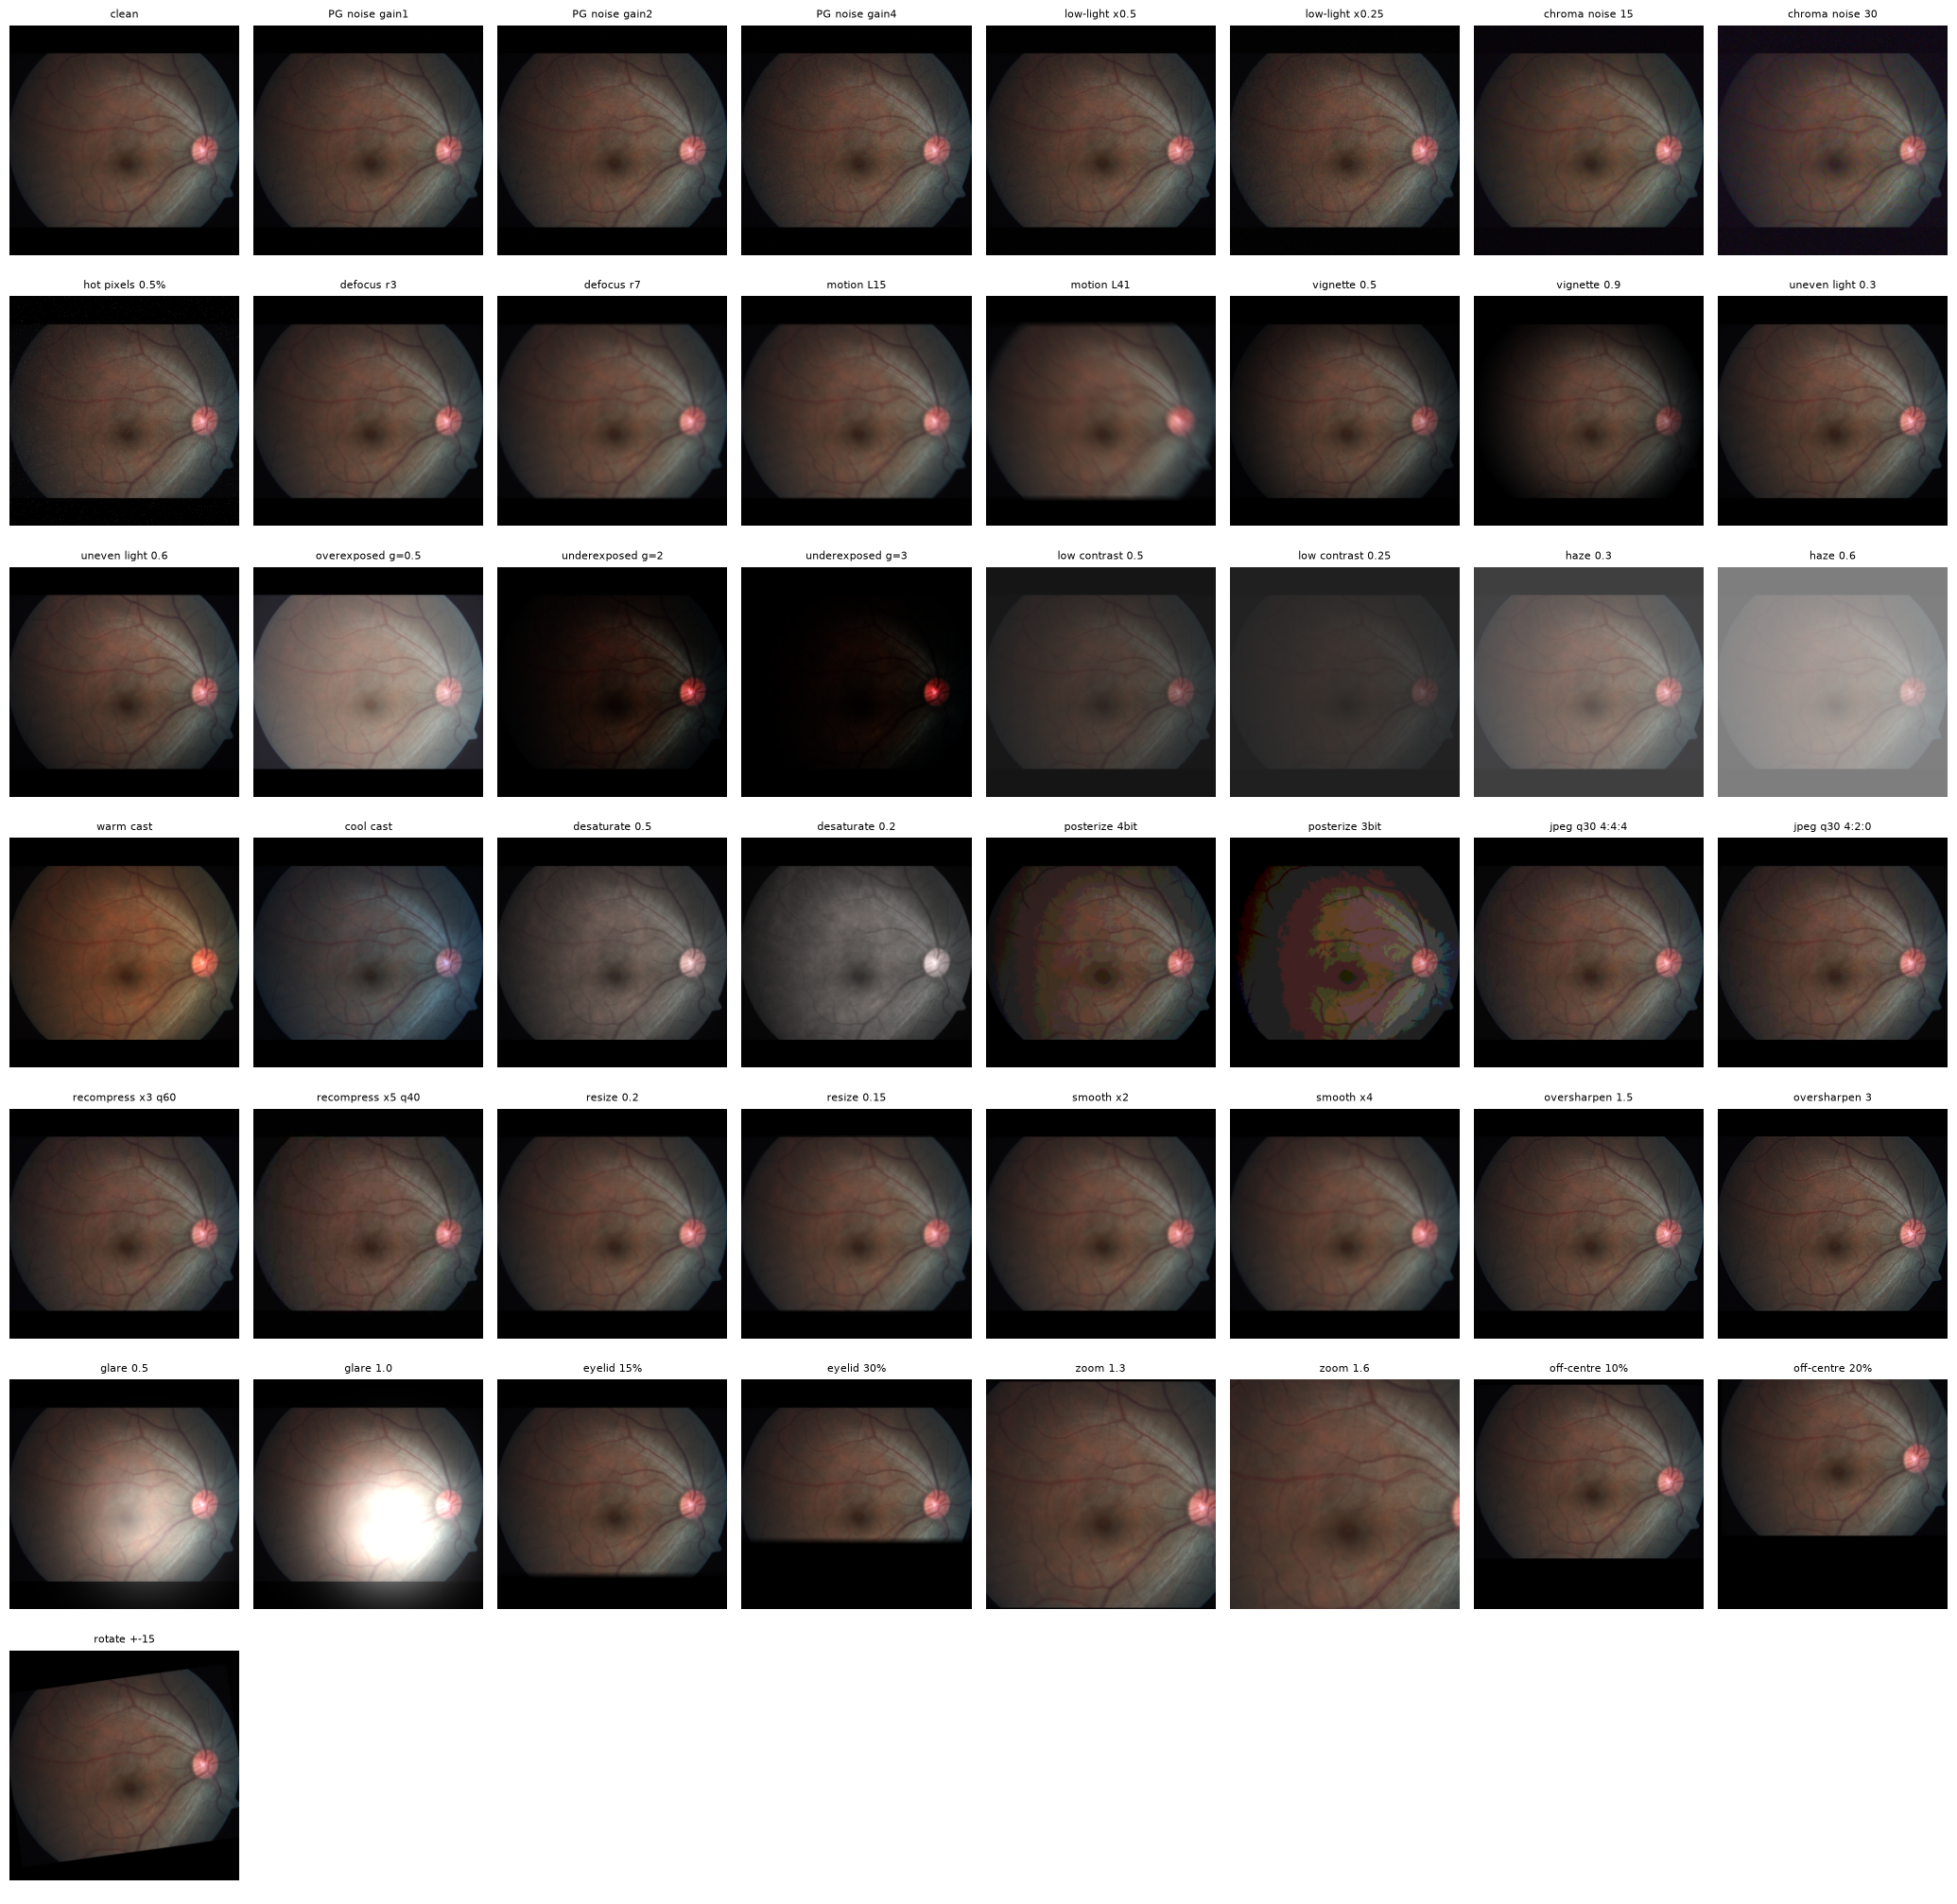

In [15]:
# Degradation catalogue (ALL_CONDITIONS), the development subset (150 images per class from the policy split) and a visual check.
GB = lambda s: ('gauss_blur', dict(sigma=s)); GN = lambda s: ('gauss_noise', dict(sigma=s))
RS = lambda s: ('resize', dict(scale=s));     JP = lambda q: ('jpeg', dict(q=q))
OLD_CONDITIONS = {      # first sweep, now expressed as specs: blur -> noise -> resize -> JPEG
 'blur s=1.5': [GB(1.5)], 'blur s=3': [GB(3)], 'blur s=5': [GB(5)],
 'noise 8': [GN(8)], 'noise 20': [GN(20)], 'noise 40': [GN(40)],
 'jpeg q=50': [JP(50)], 'jpeg q=20': [JP(20)], 'jpeg q=10': [JP(10)],
 'resize 0.5': [RS(0.5)], 'resize 0.3': [RS(0.3)],
 'combo mild': [GB(1.5), GN(8), RS(0.75), JP(70)],
 'combo moderate': [GB(3), GN(15), RS(0.5), JP(50)],
 'combo severe': [GB(5), GN(25), RS(0.35), JP(30)],
}
NEW_CONDITIONS = {
 'clean': [],
 'PG noise gain1': [('pg_noise', dict(gain=1))], 'PG noise gain2': [('pg_noise', dict(gain=2))],
 'PG noise gain4': [('pg_noise', dict(gain=4))],
 'low-light x0.5': [('lowlight', dict(dark=0.5))], 'low-light x0.25': [('lowlight', dict(dark=0.25))],
 'chroma noise 15': [('chroma_noise', dict(sigma=15))], 'chroma noise 30': [('chroma_noise', dict(sigma=30))],
 'hot pixels 0.5%': [('saltpepper', dict(frac=0.005))],
 'defocus r3': [('defocus', dict(radius=3))], 'defocus r7': [('defocus', dict(radius=7))],
 'motion L15': [('motion', dict(length=15))], 'motion L41': [('motion', dict(length=41))],
 'vignette 0.5': [('vignette', dict(strength=0.5))], 'vignette 0.9': [('vignette', dict(strength=0.9))],
 'uneven light 0.3': [('uneven', dict(strength=0.3))], 'uneven light 0.6': [('uneven', dict(strength=0.6))],
 'overexposed g=0.5': [('gamma', dict(g=0.5))], 'underexposed g=2': [('gamma', dict(g=2.0))],
 'underexposed g=3': [('gamma', dict(g=3.0))],
 'low contrast 0.5': [('contrast', dict(c=0.5))], 'low contrast 0.25': [('contrast', dict(c=0.25))],
 'haze 0.3': [('haze', dict(t=0.3))], 'haze 0.6': [('haze', dict(t=0.6))],
 'warm cast': [('wb', dict(r=1.2, g=1.0, b=0.8))], 'cool cast': [('wb', dict(r=0.8, g=1.0, b=1.2))],
 'desaturate 0.5': [('saturation', dict(s=0.5))], 'desaturate 0.2': [('saturation', dict(s=0.2))],
 'posterize 4bit': [('posterize', dict(bits=4))], 'posterize 3bit': [('posterize', dict(bits=3))],
 'jpeg q30 4:4:4': [('jpeg', dict(q=30, sub=0))], 'jpeg q30 4:2:0': [('jpeg', dict(q=30, sub=2))],
 'recompress x3 q60': [('recompress', dict(rounds=3, q=60))], 'recompress x5 q40': [('recompress', dict(rounds=5, q=40))],
 'resize 0.2': [('resize', dict(scale=0.2))], 'resize 0.15': [('resize', dict(scale=0.15))],
 'smooth x2': [('smooth', dict(passes=2))], 'smooth x4': [('smooth', dict(passes=4))],
 'oversharpen 1.5': [('oversharp', dict(amt=1.5))], 'oversharpen 3': [('oversharp', dict(amt=3.0))],
 'glare 0.5': [('glare', dict(strength=0.5))], 'glare 1.0': [('glare', dict(strength=1.0))],
 'eyelid 15%': [('eyelid', dict(frac=0.15))], 'eyelid 30%': [('eyelid', dict(frac=0.30))],
 'zoom 1.3': [('zoom', dict(z=1.3))], 'zoom 1.6': [('zoom', dict(z=1.6))],
 'off-centre 10%': [('shift', dict(frac=0.10))], 'off-centre 20%': [('shift', dict(frac=0.20))],
 'rotate +-15': [('rotate', dict(deg=15))],
}
ALL_CONDITIONS = {**NEW_CONDITIONS, **OLD_CONDITIONS}
print(len(ALL_CONDITIONS), 'conditions')

# development pool = images the classifier never trained on
DEV_SPLIT = 'policy' if POLICY_HOLDOUT_FRAC > 0 else 'val'
dev_pool = m[(m.dataset == 'aptos') & (m.split == DEV_SPLIT)]
dev_df = dev_pool.groupby('label').sample(min(150, dev_pool.label.value_counts().min()), random_state=0)

img = cv2.cvtColor(cv2.imread(dev_df.iloc[0].master_path), cv2.COLOR_BGR2RGB)
names = list(NEW_CONDITIONS); cols = 8; nr = int(np.ceil(len(names) / cols))
fig, ax = plt.subplots(nr, cols, figsize=(2.6 * cols, 2.9 * nr))
for a in ax.ravel(): a.axis('off')
for a, n in zip(ax.ravel(), names):
    d = SpecFn(deg=NEW_CONDITIONS[n])(img)
    a.imshow(cv2.resize(d, (256, 256), interpolation=cv2.INTER_AREA)); a.set_title(n, fontsize=8)
plt.tight_layout(); plt.show()

## 12. Headroom run: how much does each degradation hurt the locked classifier? (resumable per condition)

In [16]:
# Headroom run: how much does each degradation hurt the locked classifier? Degradations with high `newmiss` are the safety-critical ones.
y_dev = dev_df.label.values
p_ref = cached_probs(dev_df, 'REF', None)
rows = []
for i, (name, spec) in enumerate(ALL_CONDITIONS.items(), 1):
    t0 = time.time()
    p = cached_probs(dev_df, 'deg__' + name, SpecFn(deg=spec) if spec else None)
    rows.append({'condition': name, **outcome(p, y_dev, p_ref)})
    print(f'[{i}/{len(ALL_CONDITIONS)}] {name:20s} newmiss {rows[-1]["newmiss"]:.3f}  newfref {rows[-1]["newfref"]:.3f}  '
          f'auc {rows[-1]["auc"]:.3f}  ({time.time()-t0:.0f}s)', flush=True)
headroom = pd.DataFrame(rows).set_index('condition')
headroom['auc_drop'] = headroom.loc['clean', 'auc'] - headroom['auc']
headroom = headroom.round(3); headroom.to_csv(SAVE / 'headroom_all_degradations.csv')
headroom.sort_values('newmiss', ascending=False)

[1/63] clean                newmiss 0.000  newfref 0.000  auc 0.987  (0s)
[2/63] PG noise gain1       newmiss 0.282  newfref 0.076  auc 0.910  (0s)
[3/63] PG noise gain2       newmiss 0.374  newfref 0.393  auc 0.644  (0s)
[4/63] PG noise gain4       newmiss 0.885  newfref 0.090  auc 0.577  (0s)
[5/63] low-light x0.5       newmiss 0.641  newfref 0.241  auc 0.622  (0s)
[6/63] low-light x0.25      newmiss 0.679  newfref 0.076  auc 0.684  (0s)
[7/63] chroma noise 15      newmiss 0.168  newfref 0.014  auc 0.959  (0s)
[8/63] chroma noise 30      newmiss 0.985  newfref 0.000  auc 0.721  (0s)
[9/63] hot pixels 0.5%      newmiss 0.115  newfref 0.103  auc 0.951  (0s)
[10/63] defocus r3           newmiss 0.015  newfref 0.097  auc 0.972  (0s)
[11/63] defocus r7           newmiss 0.046  newfref 0.359  auc 0.875  (0s)
[12/63] motion L15           newmiss 0.000  newfref 0.359  auc 0.941  (0s)
[13/63] motion L41           newmiss 0.031  newfref 0.607  auc 0.820  (0s)
[14/63] vignette 0.5         newmi

,auc,sens,spec,newmiss,newfref,flip,auc_drop
condition,,,,,,,
chroma noise 30,0.721,0.013,1.000,0.985,0.000,0.447,0.266
haze 0.6,0.907,0.013,1.000,0.985,0.000,0.447,0.080
PG noise gain4,0.577,0.113,0.900,0.885,0.090,0.447,0.410
low-light x0.25,0.684,0.327,0.927,0.679,0.076,0.373,0.303
low-light x0.5,0.622,0.347,0.753,0.641,0.241,0.423,0.365
...,...,...,...,...,...,...,...
smooth x4,0.844,0.993,0.367,0.008,0.621,0.367,0.143
resize 0.3,0.983,0.913,0.953,0.008,0.021,0.040,0.004
motion L15,0.941,0.993,0.620,0.000,0.359,0.233,0.046


## 13. Restoration components + candidate pipelines
Reference colour distribution comes from clean classifier-training images. Pipelines are plain data (`[(op, params), ...]`), so the same specs can later be actions for a search or RL policy. Add components by registering a function with `@res('name')` in `dr_ops.py`.

In [17]:
# Clean colour reference (mean per-channel CDF of 200 training images) + the candidate restoration pipelines (CHAINS) and scenarios (SCEN).
ref_paths = m[(m.dataset == 'aptos') & (m.split == 'train')].sample(200, random_state=0).master_path.tolist()
if not Path(os.environ['DR_REF_PATH']).exists(): dr_ops.build_ref(ref_paths, os.environ['DR_REF_PATH'])

CHAINS = {
 'none': [],
 'nlm8': [('nlm', dict(h=8))], 'nlm15': [('nlm', dict(h=15))],
 'wavelet10': [('wavelet', dict(sigma=10))],
 'wiener2': [('wiener', dict(sigma=2.0))],
 'histmatch': [('hist_match', dict(alpha=1.0))],
 'clahe2': [('clahe', dict(clip=2.0))],
 'gamma_auto': [('gamma_auto', {})],
 'color_match': [('color_match', {})],
 'dehaze': [('dehaze', {})],
 'flatten': [('flatten', {})],
 'nlm15>histmatch': [('nlm', dict(h=15)), ('hist_match', dict(alpha=1.0))],
 'histmatch>nlm15': [('hist_match', dict(alpha=1.0)), ('nlm', dict(h=15))],
 'gamma_auto>nlm15': [('gamma_auto', {}), ('nlm', dict(h=15))],
}
# degradations that mattered in the headroom run (safety failures) + clean (harm check) + two false-referral cases
SCEN = ['clean', 'PG noise gain1', 'PG noise gain2', 'low-light x0.5', 'haze 0.6', 'underexposed g=3', 'underexposed g=2',
        'low contrast 0.25', 'desaturate 0.2', 'vignette 0.9', 'overexposed g=0.5', 'oversharpen 3', 'motion L41']
print(len(CHAINS), 'pipelines x', len(SCEN), 'scenarios =', len(CHAINS) * len(SCEN), 'runs')

14 pipelines x 13 scenarios = 182 runs


## 14. Restoration grid: every pipeline on every degradation (resumable per run)
Slow part: non-local means and wavelet on 1024-px images. Lower `RESTORE_N_PER_CLASS` for a quicker first pass.

In [18]:
# Restoration grid: every pipeline on every scenario (50 images per class). Slow because of NLM / wavelet at 1024 px; each run is cached.
RESTORE_N_PER_CLASS = 50
rs_df = dev_pool.groupby('label').sample(min(RESTORE_N_PER_CLASS, dev_pool.label.value_counts().min()), random_state=1)
yr = rs_df.label.values
pr_ref = cached_probs(rs_df, 'REF', None)
grid, total, k = {}, len(SCEN) * len(CHAINS), 0
for sc in SCEN:
    for ch, chain in CHAINS.items():
        k += 1; t0 = time.time()
        p = cached_probs(rs_df, f'rest__{sc}__{ch}', SpecFn(deg=ALL_CONDITIONS[sc], chain=chain))
        grid[(sc, ch)] = outcome(p, yr, pr_ref)
        print(f'[{k}/{total}] {sc} | {ch} | newmiss {grid[(sc, ch)]["newmiss"]:.3f}  newfref {grid[(sc, ch)]["newfref"]:.3f}  '
              f'({time.time()-t0:.0f}s)', flush=True)

[1/182] clean | none | newmiss 0.000  newfref 0.000  (18s)
[2/182] clean | nlm8 | newmiss 0.000  newfref 0.438  (46s)
[3/182] clean | nlm15 | newmiss 0.000  newfref 0.396  (44s)
[4/182] clean | wavelet10 | newmiss 0.111  newfref 0.125  (33s)
[5/182] clean | wiener2 | newmiss 0.022  newfref 0.062  (24s)
[6/182] clean | histmatch | newmiss 0.067  newfref 0.125  (15s)
[7/182] clean | clahe2 | newmiss 0.311  newfref 0.000  (15s)
[8/182] clean | gamma_auto | newmiss 0.022  newfref 0.000  (17s)
[9/182] clean | color_match | newmiss 0.156  newfref 0.062  (16s)
[10/182] clean | dehaze | newmiss 0.044  newfref 0.000  (23s)
[11/182] clean | flatten | newmiss 0.044  newfref 0.000  (84s)
[12/182] clean | nlm15>histmatch | newmiss 0.000  newfref 0.917  (45s)
[13/182] clean | histmatch>nlm15 | newmiss 0.000  newfref 0.875  (44s)
[14/182] clean | gamma_auto>nlm15 | newmiss 0.000  newfref 0.333  (48s)
[15/182] PG noise gain1 | none | newmiss 0.333  newfref 0.042  (27s)
[16/182] PG noise gain1 | nlm8 |

## 15. Is there a single pipeline that is safe for every degradation?
`nm` / `nf` = newmiss / newfref for every (pipeline, degradation). The summary ranks pipelines by **worst-case** newmiss, and compares the best single pipeline with a per-degradation oracle. The gap between them is the value of choosing the pipeline per image. Oracle values are optimistic because the minimum over many pipelines is selected on the same images.

In [20]:
# Is there one pipeline that is safe everywhere? Compare best single pipeline, per-degradation oracle and doing nothing.
nm = pd.DataFrame({sc: {ch: grid[(sc, ch)]['newmiss'] for ch in CHAINS} for sc in SCEN})
nf = pd.DataFrame({sc: {ch: grid[(sc, ch)]['newfref'] for ch in CHAINS} for sc in SCEN})
summ = pd.DataFrame({'mean_newmiss': nm.mean(axis=1), 'worst_newmiss': nm.max(axis=1), 'clean_newmiss': nm['clean'],
                     'mean_newfref': nf.mean(axis=1), 'worst_newfref': nf.max(axis=1)}).round(3).sort_values('worst_newmiss')
safe = [c for c in CHAINS if nm.loc[c, 'clean'] <= 0.05 and nf.loc[c, 'clean'] <= 0.05]
print('clean-safe pipelines:', safe); display(summ.loc[safe])
os_ = nm.loc[safe].min()
print('oracle among clean-safe | mean', round(os_.mean(), 3), '| worst', round(os_.max(), 3))
# oracle: per degradation, the pipeline with fewest new misses among those that add <= 5 points of false referrals vs 'none'
orc = pd.Series({sc: nm.loc[nf.index[nf[sc] <= nf.loc['none', sc] + 0.05], sc].min() for sc in SCEN})
print('best single pipeline, mean newmiss :', summ.mean_newmiss.min(), '| worst-case of best-by-worst:', summ.worst_newmiss.min())
print('per-degradation oracle, mean newmiss:', round(orc.mean(), 3), '| worst:', round(orc.max(), 3))
print('doing nothing           mean newmiss:', round(nm.loc['none'].mean(), 3), '| worst:', round(nm.loc['none'].max(), 3))
nm.round(2).to_csv(SAVE / 'restore_newmiss.csv'); nf.round(2).to_csv(SAVE / 'restore_newfref.csv'); summ.to_csv(SAVE / 'restore_summary.csv')
display(summ); display(nm.round(2)); display(nf.round(2))

clean-safe pipelines: ['none', 'gamma_auto', 'dehaze', 'flatten']


,mean_newmiss,worst_newmiss,clean_newmiss,mean_newfref,worst_newfref
none,0.315,0.933,0.000,0.114,0.625
gamma_auto,0.154,0.644,0.022,0.146,0.750
dehaze,0.267,0.800,0.044,0.144,0.750
flatten,0.397,1.000,0.044,0.096,0.771


oracle among clean-safe | mean 0.133 | worst 0.644
best single pipeline, mean newmiss : 0.01 | worst-case of best-by-worst: 0.067
per-degradation oracle, mean newmiss: 0.075 | worst: 0.2
doing nothing           mean newmiss: 0.315 | worst: 0.933


,mean_newmiss,worst_newmiss,clean_newmiss,mean_newfref,worst_newfref
nlm15>histmatch,0.010,0.067,0.000,0.869,1.000
histmatch>nlm15,0.022,0.133,0.000,0.748,0.979
gamma_auto>nlm15,0.062,0.400,0.000,0.309,0.542
gamma_auto,0.154,0.644,0.022,0.146,0.750
histmatch,0.265,0.711,0.067,0.288,0.958
color_match,0.287,0.733,0.156,0.151,0.688
dehaze,0.267,0.800,0.044,0.144,0.750
clahe2,0.409,0.889,0.311,0.112,0.604
none,0.315,0.933,0.000,0.114,0.625
wiener2,0.398,0.933,0.022,0.173,0.729


,clean,PG noise gain1,PG noise gain2,low-light x0.5,haze 0.6,underexposed g=3,underexposed g=2,low contrast 0.25,desaturate 0.2,vignette 0.9,overexposed g=0.5,oversharpen 3,motion L41
none,0.00,0.33,0.56,0.76,0.93,0.42,0.42,0.20,0.11,0.18,0.04,0.13,0.00
nlm8,0.00,0.00,0.00,0.09,0.98,0.16,0.13,0.07,0.38,0.00,0.02,0.00,0.04
nlm15,0.00,0.02,0.02,0.02,0.98,0.27,0.18,0.11,0.64,0.04,0.04,0.00,0.04
wavelet10,0.11,0.18,0.18,0.20,1.00,0.71,0.42,0.98,0.62,0.67,0.29,0.13,0.44
wiener2,0.02,0.42,0.69,0.78,0.93,0.47,0.49,0.13,0.20,0.40,0.09,0.56,0.00
histmatch,0.07,0.62,0.60,0.62,0.11,0.20,0.07,0.09,0.20,0.11,0.04,0.71,0.00
clahe2,0.31,0.64,0.84,0.89,0.51,0.22,0.38,0.20,0.16,0.24,0.18,0.56,0.18
gamma_auto,0.02,0.11,0.40,0.64,0.09,0.09,0.07,0.18,0.22,0.00,0.02,0.13,0.02
color_match,0.16,0.31,0.53,0.73,0.40,0.00,0.07,0.36,0.47,0.22,0.20,0.24,0.04
dehaze,0.04,0.42,0.67,0.80,0.13,0.40,0.42,0.09,0.09,0.09,0.02,0.27,0.02


,clean,PG noise gain1,PG noise gain2,low-light x0.5,haze 0.6,underexposed g=3,underexposed g=2,low contrast 0.25,desaturate 0.2,vignette 0.9,overexposed g=0.5,oversharpen 3,motion L41
none,0.00,0.04,0.38,0.19,0.00,0.02,0.00,0.04,0.04,0.02,0.12,0.00,0.62
nlm8,0.44,0.42,0.29,0.52,0.00,0.06,0.08,0.33,0.12,0.40,0.23,0.44,0.38
nlm15,0.40,0.27,0.23,0.40,0.00,0.08,0.10,0.29,0.15,0.48,0.21,0.10,0.40
wavelet10,0.12,0.04,0.02,0.04,0.00,0.02,0.02,0.00,0.02,0.04,0.06,0.04,0.29
wiener2,0.06,0.38,0.19,0.06,0.00,0.00,0.02,0.12,0.23,0.00,0.46,0.00,0.73
histmatch,0.12,0.35,0.54,0.62,0.12,0.12,0.10,0.10,0.12,0.19,0.12,0.25,0.96
clahe2,0.00,0.08,0.00,0.00,0.00,0.10,0.00,0.02,0.60,0.00,0.19,0.00,0.46
gamma_auto,0.00,0.10,0.29,0.31,0.00,0.06,0.00,0.02,0.10,0.02,0.02,0.21,0.75
color_match,0.06,0.17,0.29,0.17,0.08,0.10,0.15,0.02,0.00,0.08,0.10,0.04,0.69
dehaze,0.00,0.17,0.21,0.12,0.06,0.04,0.02,0.02,0.17,0.02,0.27,0.02,0.75


## Where this goes next
1. Read section 15: if one pipeline matches the oracle, a policy is not needed; if the gap is large, per-image selection is worth building.
2. Offline policy: cost-sensitive classifier (e.g. gradient boosting) from cheap image statistics to the best pipeline.
3. RL: sequential choice of (component, strength) with a stop action, rewarded by misses and false referrals, evaluated on degradation families held out of training.

<h2>features, gate thresholds and the rule-based policy</h2>

In [21]:
# Cheap image statistics -> gate thresholds (1%/99% quantiles of CLEAN images) -> RULE policy; compared with none, best fixed pipeline and oracles.
from multiprocessing.pool import ThreadPool
MASK512 = dr_ops._disc(512, 512, 0.45)
K_LAP = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)

def image_features(rgb):                       # statistics of the DEGRADED image, at the size the classifier sees
    s = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA)
    g = s[..., 1].astype(np.float32); gray = s.mean(axis=2)
    noise = np.median(np.abs(cv2.filter2D(g, -1, K_LAP))[MASK512]) / 0.6745 / 6    # robust noise sigma (grey levels)
    return dict(noise=noise, bright=gray[MASK512].mean() / 255, contrast=gray[MASK512].std() / 255,
                sat=cv2.cvtColor(s, cv2.COLOR_RGB2HSV)[..., 1][MASK512].mean() / 255,
                dark=s.min(axis=2)[MASK512].mean() / 255)

def scenario_features(df, spec):
    fn = SpecFn(deg=spec)
    def one(p): return image_features(fn(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)))
    with ThreadPool(8) as pool: return pd.DataFrame(pool.map(one, df.master_path.tolist()))

FEAT_FILE = SAVE / f'features_{set_key(rs_df)}.pkl'
FEATS = pickle.load(open(FEAT_FILE, 'rb')) if FEAT_FILE.exists() else {}
for sc in SCEN:
    if sc not in FEATS: FEATS[sc] = scenario_features(rs_df, ALL_CONDITIONS[sc])
pickle.dump(FEATS, open(FEAT_FILE, 'wb'))

cal = m[(m.dataset == 'aptos') & (m.split == 'train')].sample(300, random_state=0)
F_cal = scenario_features(cal, [])
Q = 0.01                                        # each rule fires on about 1% of clean images
lo, hi = F_cal.quantile(Q), F_cal.quantile(1 - Q)
print(pd.DataFrame({'lo': lo, 'hi': hi}).round(4).T)

POLICY_CHAINS = {'noisy_light': 'gamma_auto>nlm15', 'noisy': 'nlm8', 'light': 'gamma_auto', 'ok': 'none'}
def make_rule_policy(lo, hi, pc=POLICY_CHAINS):
    def rule(f):
        noisy = f.noise > hi.noise
        light = (f.bright < lo.bright) or (f.bright > hi.bright) or (f.contrast < lo.contrast) or (f.dark > hi.dark)
        return pc['noisy_light' if noisy and light else 'noisy' if noisy else 'light' if light else 'ok']
    return rule
rule = make_rule_policy(lo, hi)

def load_cached(df, name):                       # exact lookup; raises if that run was never done
    return np.load(PROBS / MODEL_KEY / set_key(df) / (_safe(name) + '.npy'))

def eval_choices(scens, chooser, df=None, y=None, p_ref=None):
    df = rs_df if df is None else df; y = yr if y is None else y; p_ref = pr_ref if p_ref is None else p_ref
    rows, picks = [], {}
    for sc in scens:
        F = FEATS[sc]; choice = [chooser(sc, i, F.iloc[i]) for i in range(len(F))]
        P = {c: load_cached(df, f'rest__{sc}__{c}') for c in set(choice)}
        p = np.array([P[c][i] for i, c in enumerate(choice)])
        r = outcome(p, y, p_ref); r['restored'] = float(np.mean([c != 'none' for c in choice])); r['scenario'] = sc
        rows.append(r); picks[sc] = pd.Series(choice).value_counts().to_dict()
    return pd.DataFrame(rows).set_index('scenario'), picks

def image_oracle(sc, chains, Cm=5.0, Cf=1.0):    # per-image best pipeline using privileged info (optimistic upper bound)
    pc = pr_ref >= thr; order = ['none'] + [c for c in chains if c != 'none']; M = []
    for c in order:
        pred = load_cached(rs_df, f'rest__{sc}__{c}') >= thr
        M.append(Cm * ((yr == 1) & pc & ~pred) + Cf * ((yr == 0) & ~pc & pred))
    return [order[j] for j in np.stack(M).argmin(axis=0)]

def summarize(res, label):
    return dict(policy=label, mean_newmiss=res.newmiss.mean(), worst_newmiss=res.newmiss.max(),
                mean_newfref=res.newfref.mean(), worst_newfref=res.newfref.max(),
                clean_newmiss=res.newmiss.get('clean', np.nan), clean_newfref=res.newfref.get('clean', np.nan))

scen_best = {sc: nm.loc[nf.index[nf[sc] <= nf.loc['none', sc] + 0.05], sc].idxmin() for sc in SCEN}
choosers = {'none': lambda sc, i, f: 'none', 'gamma_auto (best fixed)': lambda sc, i, f: 'gamma_auto',
            'RULE policy': lambda sc, i, f: rule(f), 'scenario oracle': lambda sc, i, f: scen_best[sc], 'image oracle': None}
R, picks = {}, {}
for name, ch in choosers.items():
    if ch is None:
        ic = {sc: image_oracle(sc, list(CHAINS)) for sc in SCEN}
        R[name], picks[name] = eval_choices(SCEN, lambda sc, i, f: ic[sc][i])
    else:
        R[name], picks[name] = eval_choices(SCEN, ch)
summary_A = pd.DataFrame([summarize(r, n) for n, r in R.items()]).set_index('policy').round(3)
display(summary_A)
display(pd.DataFrame({n: r.newmiss for n, r in R.items()}).round(2))
print('what the rule policy chose in each scenario:'); [print(f'  {sc:20s} {picks["RULE policy"][sc]}') for sc in SCEN]
summary_A.to_csv(SAVE / 'rule_policy_summary.csv')

     noise  bright  contrast     sat    dark
lo  0.4942  0.1300    0.0399  0.2361  0.0049
hi  1.2355  0.4594    0.1541  0.9895  0.2815


,mean_newmiss,worst_newmiss,mean_newfref,worst_newfref,clean_newmiss,clean_newfref
policy,,,,,,
none,0.315,0.933,0.114,0.625,0.000,0.0
gamma_auto (best fixed),0.154,0.644,0.146,0.750,0.022,0.0
RULE policy,0.084,0.200,0.197,0.646,0.022,0.0
scenario oracle,0.075,0.200,0.090,0.625,0.000,0.0
image oracle,0.000,0.000,0.003,0.042,0.000,0.0


,none,gamma_auto (best fixed),RULE policy,scenario oracle,image oracle
scenario,,,,,
clean,0.00,0.02,0.02,0.00,0.0
PG noise gain1,0.33,0.11,0.00,0.18,0.0
PG noise gain2,0.56,0.40,0.00,0.00,0.0
low-light x0.5,0.76,0.64,0.07,0.20,0.0
haze 0.6,0.93,0.09,0.09,0.09,0.0
underexposed g=3,0.42,0.09,0.11,0.09,0.0
underexposed g=2,0.42,0.07,0.20,0.07,0.0
low contrast 0.25,0.20,0.18,0.18,0.09,0.0
desaturate 0.2,0.11,0.22,0.20,0.11,0.0


what the rule policy chose in each scenario:
  clean                {'none': 95, 'gamma_auto': 5}
  PG noise gain1       {'nlm8': 95, 'gamma_auto>nlm15': 5}
  PG noise gain2       {'nlm8': 96, 'gamma_auto>nlm15': 4}
  low-light x0.5       {'nlm8': 96, 'gamma_auto>nlm15': 4}
  haze 0.6             {'gamma_auto': 100}
  underexposed g=3     {'gamma_auto': 87, 'none': 13}
  underexposed g=2     {'none': 52, 'gamma_auto': 48}
  low contrast 0.25    {'gamma_auto': 100}
  desaturate 0.2       {'gamma_auto': 86, 'none': 14}
  vignette 0.9         {'none': 85, 'gamma_auto': 15}
  overexposed g=0.5    {'gamma_auto': 74, 'none': 23, 'nlm8': 3}
  oversharpen 3        {'nlm8': 91, 'none': 5, 'gamma_auto>nlm15': 4}
  motion L41           {'none': 95, 'gamma_auto': 5}


<h2>Compound degradations and the order test</h2>

In [22]:
# Compound degradations (several at once) and the order test: does applying denoise before/after gamma or dehaze matter?
COMPOUND = {
 'lowlight x0.5 + haze 0.3':            [('lowlight', dict(dark=0.5)), ('haze', dict(t=0.3))],
 'underexp g=2 + PG noise g1':          [('gamma', dict(g=2.0)), ('pg_noise', dict(gain=1))],
 'PG noise g1 + vignette 0.9 + jpeg q40': [('pg_noise', dict(gain=1)), ('vignette', dict(strength=0.9)), ('jpeg', dict(q=40))],
 'haze 0.3 + PG noise g1 + jpeg q30':   [('haze', dict(t=0.3)), ('pg_noise', dict(gain=1)), ('jpeg', dict(q=30))],
 'defocus r3 + PG noise g1 + jpeg q40': [('defocus', dict(radius=3)), ('pg_noise', dict(gain=1)), ('jpeg', dict(q=40))],
}
ALL_CONDITIONS.update(COMPOUND)
CHAINS_C = {k: CHAINS[k] for k in ['none', 'gamma_auto', 'nlm8', 'nlm15', 'gamma_auto>nlm15', 'dehaze']}
CHAINS_C.update({'nlm15>gamma_auto': [('nlm', dict(h=15)), ('gamma_auto', {})],     # reversed orders for the order test
                 'dehaze>nlm15': [('dehaze', {}), ('nlm', dict(h=15))],
                 'nlm15>dehaze': [('nlm', dict(h=15)), ('dehaze', {})]})
grid_c, tot, k = {}, len(COMPOUND) * len(CHAINS_C), 0
for sc in COMPOUND:
    for ch, chain in CHAINS_C.items():
        k += 1; t0 = time.time()
        p = cached_probs(rs_df, f'rest__{sc}__{ch}', SpecFn(deg=ALL_CONDITIONS[sc], chain=chain))
        grid_c[(sc, ch)] = outcome(p, yr, pr_ref)
        print(f'[{k}/{tot}] {sc} | {ch} | newmiss {grid_c[(sc, ch)]["newmiss"]:.3f}  newfref {grid_c[(sc, ch)]["newfref"]:.3f}  ({time.time()-t0:.0f}s)', flush=True)
for sc in COMPOUND:
    if sc not in FEATS: FEATS[sc] = scenario_features(rs_df, ALL_CONDITIONS[sc])
pickle.dump(FEATS, open(FEAT_FILE, 'wb'))
nmC = pd.DataFrame({sc: {ch: grid_c[(sc, ch)]['newmiss'] for ch in CHAINS_C} for sc in COMPOUND})
nfC = pd.DataFrame({sc: {ch: grid_c[(sc, ch)]['newfref'] for ch in CHAINS_C} for sc in COMPOUND})
display(nmC.round(2)); display(nfC.round(2))

[1/45] lowlight x0.5 + haze 0.3 | none | newmiss 0.111  newfref 0.125  (37s)
[2/45] lowlight x0.5 + haze 0.3 | gamma_auto | newmiss 0.289  newfref 0.500  (34s)
[3/45] lowlight x0.5 + haze 0.3 | nlm8 | newmiss 0.156  newfref 0.167  (58s)
[4/45] lowlight x0.5 + haze 0.3 | nlm15 | newmiss 0.178  newfref 0.146  (56s)
[5/45] lowlight x0.5 + haze 0.3 | gamma_auto>nlm15 | newmiss 0.156  newfref 0.083  (59s)
[6/45] lowlight x0.5 + haze 0.3 | dehaze | newmiss 0.733  newfref 0.208  (33s)
[7/45] lowlight x0.5 + haze 0.3 | nlm15>gamma_auto | newmiss 0.178  newfref 0.062  (57s)
[8/45] lowlight x0.5 + haze 0.3 | dehaze>nlm15 | newmiss 0.111  newfref 0.458  (62s)
[9/45] lowlight x0.5 + haze 0.3 | nlm15>dehaze | newmiss 0.156  newfref 0.146  (62s)
[10/45] underexp g=2 + PG noise g1 | none | newmiss 0.422  newfref 0.000  (24s)
[11/45] underexp g=2 + PG noise g1 | gamma_auto | newmiss 0.489  newfref 0.083  (27s)
[12/45] underexp g=2 + PG noise g1 | nlm8 | newmiss 0.133  newfref 0.062  (53s)
[13/45] unde

,lowlight x0.5 + haze 0.3,underexp g=2 + PG noise g1,PG noise g1 + vignette 0.9 + jpeg q40,haze 0.3 + PG noise g1 + jpeg q30,defocus r3 + PG noise g1 + jpeg q40
none,0.11,0.42,0.16,0.20,0.07
gamma_auto,0.29,0.49,0.11,0.04,0.04
nlm8,0.16,0.13,0.00,0.04,0.02
nlm15,0.18,0.29,0.02,0.07,0.04
gamma_auto>nlm15,0.16,0.02,0.02,0.04,0.02
dehaze,0.73,0.44,0.02,0.04,0.02
nlm15>gamma_auto,0.18,0.00,0.02,0.04,0.02
dehaze>nlm15,0.11,0.31,0.02,0.00,0.04
nlm15>dehaze,0.16,0.18,0.02,0.02,0.04


,lowlight x0.5 + haze 0.3,underexp g=2 + PG noise g1,PG noise g1 + vignette 0.9 + jpeg q40,haze 0.3 + PG noise g1 + jpeg q30,defocus r3 + PG noise g1 + jpeg q40
none,0.12,0.00,0.06,0.15,0.10
gamma_auto,0.50,0.08,0.21,0.27,0.08
nlm8,0.17,0.06,0.48,0.60,0.23
nlm15,0.15,0.00,0.44,0.40,0.17
gamma_auto>nlm15,0.08,0.38,0.33,0.21,0.10
dehaze,0.21,0.00,0.40,0.52,0.19
nlm15>gamma_auto,0.06,0.21,0.33,0.23,0.12
dehaze>nlm15,0.46,0.02,0.73,0.58,0.46
nlm15>dehaze,0.15,0.15,0.65,0.46,0.31


<h2>RL-necessity tests</h2>

In [23]:
# Is RL needed? Test 1: does the rule close >= 80% of the gap to the scenario oracle; Test 2: does order matter; Test 3: does denoiser strength matter.
cap = lambda nmT, nfT, sc: nmT.loc[nfT.index[nfT[sc] <= nfT.loc['none', sc] + 0.05], sc].idxmin()
scen_best_C = {sc: cap(nmC, nfC, sc) for sc in COMPOUND}
ic_C = {sc: image_oracle(sc, list(CHAINS_C)) for sc in COMPOUND}
RC = {'none': eval_choices(list(COMPOUND), lambda sc, i, f: 'none')[0],
      'gamma_auto (best fixed)': eval_choices(list(COMPOUND), lambda sc, i, f: 'gamma_auto')[0],
      'RULE policy': eval_choices(list(COMPOUND), lambda sc, i, f: rule(f))[0],
      'scenario oracle': eval_choices(list(COMPOUND), lambda sc, i, f: scen_best_C[sc])[0],
      'image oracle': eval_choices(list(COMPOUND), lambda sc, i, f: ic_C[sc][i])[0]}
summary_C = pd.DataFrame([summarize(r, n) for n, r in RC.items()]).set_index('policy').round(3)
display(summary_C)

def gap_closed(S):
    n, r, o = S.loc['none', 'mean_newmiss'], S.loc['RULE policy', 'mean_newmiss'], S.loc['scenario oracle', 'mean_newmiss']
    return (n - r) / max(n - o, 1e-9)
g1, g2 = gap_closed(summary_A), gap_closed(summary_C)
extra_fref = summary_A.loc['RULE policy', 'clean_newfref'] - summary_A.loc['none', 'clean_newfref']

pairs = [('gamma_auto>nlm15', 'nlm15>gamma_auto'), ('dehaze>nlm15', 'nlm15>dehaze')]
order_tab = pd.DataFrame({f'{a}  vs  {b}': {sc: abs(nmC.loc[a, sc] - nmC.loc[b, sc]) for sc in COMPOUND} for a, b in pairs}).round(3)
display(order_tab); order_eff = float(order_tab.values.max())

noisy_sc = [s for s in SCEN if s.startswith(('PG', 'low-light'))]
strength_eff = float((nm.loc['nlm8', noisy_sc] - nm.loc['nlm15', noisy_sc]).abs().max())

print(f'\nTest 1 selection : rule closes {g1:.0%} (single) and {g2:.0%} (compound) of the none->scenario-oracle gap; '
      f'extra clean false referrals {extra_fref:+.2f}')
print(f'Test 2 order     : largest newmiss difference between reversed orders = {order_eff:.3f}')
print(f'Test 3 strength  : largest newmiss difference between nlm8 and nlm15 on noisy scenarios = {strength_eff:.3f}')
no_rl = (bool(g1 >= 0.8 and g2 >= 0.8 and extra_fref <= 0.05), bool(order_eff < 0.05), bool(strength_eff < 0.05))
print('\nRL NOT needed at this stage if all three hold:', no_rl)
print('=> verdict:', 'a rule/learned selector is enough' if all(no_rl) else 'there is structure a simple rule misses; examine which test failed before building RL')

,mean_newmiss,worst_newmiss,mean_newfref,worst_newfref,clean_newmiss,clean_newfref
policy,,,,,,
none,0.191,0.422,0.088,0.146,NaN,NaN
gamma_auto (best fixed),0.196,0.489,0.229,0.500,NaN,NaN
RULE policy,0.102,0.178,0.167,0.229,NaN,NaN
scenario oracle,0.156,0.289,0.088,0.146,NaN,NaN
image oracle,0.000,0.000,0.021,0.042,NaN,NaN


,gamma_auto>nlm15 vs nlm15>gamma_auto,dehaze>nlm15 vs nlm15>dehaze
lowlight x0.5 + haze 0.3,0.022,0.044
underexp g=2 + PG noise g1,0.022,0.133
PG noise g1 + vignette 0.9 + jpeg q40,0.000,0.000
haze 0.3 + PG noise g1 + jpeg q30,0.000,0.022
defocus r3 + PG noise g1 + jpeg q40,0.000,0.000



Test 1 selection : rule closes 96% (single) and 254% (compound) of the none->scenario-oracle gap; extra clean false referrals +0.00
Test 2 order     : largest newmiss difference between reversed orders = 0.133
Test 3 strength  : largest newmiss difference between nlm8 and nlm15 on noisy scenarios = 0.067

RL NOT needed at this stage if all three hold: (True, False, False)
=> verdict: there is structure a simple rule misses; examine which test failed before building RL


In [24]:
# Learned selector: one gradient-boosting regressor per pipeline predicts its cost (CM x new misses + CF x new false referrals);
# choose the cheapest and keep 'none' unless another is clearly better. A = unseen images, B = unseen images AND unseen degradation type.
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold
CM, CF = 5.0, 1.0            # cost of one new miss vs one new false referral: a stated design choice, try 2 and 10 as well

YY, XX = np.mgrid[:512, :512]; RR = np.hypot(YY - 256, XX - 256) / 512
RING, CENT = (RR > 0.30) & (RR < 0.45), RR < 0.15
def image_features2(rgb):                       # Cell A features + spatial / colour / sharpness / range features
    f = image_features(rgb)
    s = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA); gray = s.mean(axis=2)
    R, G, B = [s[..., i].astype(np.float32) for i in range(3)]
    f.update(ring=gray[RING].mean() / (gray[CENT].mean() + 1), rg=R[MASK512].mean() / (G[MASK512].mean() + 1),
             bg=B[MASK512].mean() / (G[MASK512].mean() + 1), lap=float(cv2.Laplacian(gray.astype(np.float32), cv2.CV_32F)[MASK512].var()),
             p5=np.percentile(gray[MASK512], 5) / 255, p95=np.percentile(gray[MASK512], 95) / 255)
    return f
def scenario_features2(df, spec):
    fn = SpecFn(deg=spec)
    def one(p): return image_features2(fn(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)))
    with ThreadPool(8) as pool: return pd.DataFrame(pool.map(one, df.master_path.tolist()))

ALLSC = SCEN + list(COMPOUND)
F2_FILE = SAVE / f'features2_{set_key(rs_df)}.pkl'
FEATS2 = pickle.load(open(F2_FILE, 'rb')) if F2_FILE.exists() else {}
for sc in ALLSC:
    if sc not in FEATS2: FEATS2[sc] = scenario_features2(rs_df, ALL_CONDITIONS[sc])
pickle.dump(FEATS2, open(F2_FILE, 'wb'))

CAND = ['none', 'gamma_auto', 'nlm8', 'nlm15', 'gamma_auto>nlm15', 'dehaze']     # pipelines available for singles AND compounds
pc = pr_ref >= thr; tp_c = (yr == 1) & pc; tn_c = (yr == 0) & ~pc; FN = list(FEATS2[ALLSC[0]].columns)
X, MISS, FREF, SCI, IMG, RULE = [], [], [], [], [], []
for si, sc in enumerate(ALLSC):
    pred = np.stack([load_cached(rs_df, f'rest__{sc}__{c}') for c in CAND], axis=1) >= thr      # images x candidates
    MISS.append(((~pred) & tp_c[:, None]).astype(float)); FREF.append((pred & tn_c[:, None]).astype(float))
    X.append(FEATS2[sc][FN].values); SCI += [si] * len(rs_df); IMG += list(range(len(rs_df)))
    RULE += [CAND.index(rule(FEATS2[sc].iloc[i])) for i in range(len(rs_df))]
X, MISS, FREF, SCI, IMG, RULE = np.vstack(X), np.vstack(MISS), np.vstack(FREF), np.array(SCI), np.array(IMG), np.array(RULE)
COST = CM * MISS + CF * FREF                                                                  # rows x candidates

def fit_choose(tr, te, margin=0.05):             # one regressor per pipeline predicts its cost; pick the cheapest, keep 'none' unless clearly worse
    pred = np.zeros((len(te), len(CAND)))
    for j in range(len(CAND)):
        g = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)
        pred[:, j] = g.fit(X[tr], COST[tr, j]).predict(X[te])
    return np.where(pred[:, 0] <= pred.min(axis=1) + margin, 0, pred.argmin(axis=1))

CH_A, CH_B = np.zeros(len(X), int), np.zeros(len(X), int)
for trn_img, tst_img in KFold(5, shuffle=True, random_state=0).split(np.arange(len(rs_df))):
    tr_img, te_img = np.isin(IMG, trn_img), np.isin(IMG, tst_img)
    CH_A[te_img] = fit_choose(np.where(tr_img)[0], np.where(te_img)[0])                       # A: unseen images, degradation types seen
    for si in range(len(ALLSC)):                                                              # B: unseen images AND unseen degradation
        te = np.where(te_img & (SCI == si))[0]; tr = np.where(tr_img & (SCI != si))[0]
        CH_B[te] = fit_choose(tr, te)

def evaluate(choice, label):
    rows = []
    for si, sc in enumerate(ALLSC):
        r = np.where(SCI == si)[0]; ch = choice[r]
        rows.append(dict(policy=label, scenario=sc, group='single' if si < len(SCEN) else 'compound',
                         newmiss=MISS[r, ch].sum() / max(tp_c.sum(), 1), newfref=FREF[r, ch].sum() / max(tn_c.sum(), 1),
                         cost=COST[r, ch].mean()))
    return pd.DataFrame(rows)
sc_or = np.zeros(len(X), int)
for si in range(len(ALLSC)):
    r = np.where(SCI == si)[0]; sc_or[r] = COST[r].mean(axis=0).argmin()
POL = {'none': np.zeros(len(X), int), 'gamma_auto (fixed)': np.ones(len(X), int), 'RULE policy': RULE,
       'learned, unseen images': CH_A, 'learned, unseen images + unseen degradation': CH_B,
       'scenario oracle': sc_or, 'image oracle (optimistic)': COST.argmin(axis=1)}
ev = pd.concat([evaluate(c, n) for n, c in POL.items()])
for grp in ['single', 'compound']:
    t = ev[ev.group == grp].groupby('policy', sort=False).agg(cost=('cost', 'mean'), newmiss=('newmiss', 'mean'), newfref=('newfref', 'mean'),
                                                              worst_newmiss=('newmiss', 'max'), worst_newfref=('newfref', 'max')).round(3)
    print(f'--- {grp} degradations (cost = {CM:g} x misses + {CF:g} x false referrals, per image)'); display(t)
display(ev.pivot(index='scenario', columns='policy', values='cost').round(2)[list(POL)].loc[ALLSC])

# order pairs and denoiser strength, now with BOTH metrics and signs
pr_ = ['gamma_auto>nlm15', 'nlm15>gamma_auto', 'dehaze>nlm15', 'nlm15>dehaze']
display(pd.concat({'newmiss': nmC.loc[pr_], 'newfref': nfC.loc[pr_]}).round(2))
noisy_sc = [s for s in SCEN if s.startswith(('PG', 'low-light'))]
display(pd.concat({'newmiss': nm.loc[['nlm8', 'nlm15'], noisy_sc], 'newfref': nf.loc[['nlm8', 'nlm15'], noisy_sc]}).round(2))

--- single degradations (cost = 5 x misses + 1 x false referrals, per image)


,cost,newmiss,newfref,worst_newmiss,worst_newfref
policy,,,,,
none,0.762,0.315,0.114,0.933,0.625
gamma_auto (fixed),0.416,0.154,0.146,0.644,0.750
RULE policy,0.283,0.084,0.197,0.200,0.646
"learned, unseen images",0.235,0.062,0.200,0.156,0.646
"learned, unseen images + unseen degradation",0.372,0.118,0.223,0.711,0.708
scenario oracle,0.145,0.029,0.165,0.111,0.438
image oracle (optimistic),0.019,0.003,0.024,0.022,0.167


--- compound degradations (cost = 5 x misses + 1 x false referrals, per image)


,cost,newmiss,newfref,worst_newmiss,worst_newfref
policy,,,,,
none,0.472,0.191,0.088,0.422,0.146
gamma_auto (fixed),0.550,0.196,0.229,0.489,0.500
RULE policy,0.310,0.102,0.167,0.178,0.229
"learned, unseen images",0.290,0.089,0.188,0.156,0.250
"learned, unseen images + unseen degradation",0.376,0.133,0.158,0.267,0.229
scenario oracle,0.210,0.044,0.229,0.111,0.375
image oracle (optimistic),0.020,0.004,0.021,0.022,0.042


policy,none,gamma_auto (fixed),RULE policy,"learned, unseen images","learned, unseen images + unseen degradation",scenario oracle,image oracle (optimistic)
scenario,,,,,,,
clean,0.00,0.05,0.05,0.03,0.03,0.00,0.00
PG noise gain1,0.77,0.30,0.20,0.14,0.14,0.10,0.00
PG noise gain2,1.43,1.04,0.14,0.16,0.16,0.14,0.02
low-light x0.5,1.79,1.60,0.40,0.21,0.26,0.22,0.02
haze 0.6,2.10,0.20,0.20,0.37,1.60,0.20,0.05
underexposed g=3,0.96,0.23,0.28,0.31,0.29,0.21,0.00
underexposed g=2,0.95,0.15,0.45,0.19,0.34,0.13,0.00
low contrast 0.25,0.47,0.41,0.41,0.44,0.41,0.21,0.00
desaturate 0.2,0.27,0.55,0.50,0.36,0.67,0.27,0.06


lowlight x0.5 + haze 0.3  \
newmiss gamma_auto>nlm15                      0.16   
        nlm15>gamma_auto                      0.18   
        dehaze>nlm15                          0.11   
        nlm15>dehaze                          0.16   
newfref gamma_auto>nlm15                      0.08   
        nlm15>gamma_auto                      0.06   
        dehaze>nlm15                          0.46   
        nlm15>dehaze                          0.15   

                          underexp g=2 + PG noise g1  \
newmiss gamma_auto>nlm15                        0.02   
        nlm15>gamma_auto                        0.00   
        dehaze>nlm15                            0.31   
        nlm15>dehaze                            0.18   
newfref gamma_auto>nlm15                        0.38   
        nlm15>gamma_auto                        0.21   
        dehaze>nlm15                            0.02   
        nlm15>dehaze                            0.15   

                          PG noise g1 + vignette 0.9 + jpeg q40  \
newmiss gamma_auto>nlm15                                   0.02   
        nlm15>gamma_auto                                   0.02   
        dehaze>nlm15                                       0.02   
        nlm15>dehaze                                       0.02   
newfref gamma_auto>nlm15                                   0.33   
        nlm15>gamma_auto                                   0.33   
        dehaze>nlm15                                       0.73   
        nlm15>dehaze                                       0.65   

                          haze 0.3 + PG noise g1 + jpeg q30  \
newmiss gamma_auto>nlm15                               0.04   
        nlm15>gamma_auto                               0.04   
        dehaze>nlm15                                   0.00   
        nlm15>dehaze                                   0.02   
newfref gamma_auto>nlm15                               0.21   
        nlm15>gamma_auto                               0.23   
        dehaze>nlm15                                   0.58   
        nlm15>dehaze                                   0.46   

                          defocus r3 + PG noise g1 + jpeg q40  
newmiss gamma_auto>nlm15                                 0.02  
        nlm15>gamma_auto                                 0.02  
        dehaze>nlm15                                     0.04  
        nlm15>dehaze                                     0.04  
newfref gamma_auto>nlm15                                 0.10  
        nlm15>gamma_auto                                 0.12  
        dehaze>nlm15                                     0.46  
        nlm15>dehaze                                     0.31

PG noise gain1  PG noise gain2  low-light x0.5
newmiss nlm8             0.00            0.00            0.09
        nlm15            0.02            0.02            0.02
newfref nlm8             0.42            0.29            0.52
        nlm15            0.27            0.23            0.40

<h2>Random Sampling + Gradient Boosting + CMA search pipeline</h2>

In [26]:
# %pip install -q cma

Note: you may need to restart the kernel to use updated packages.


In [27]:
%%writefile dr_rl.py
# Worker-safe module (no torch): random degradation sampler, continuous-action restorer, state features, sample worker.
# Everything works at 512 px (the classifier's input size). Noise / blur ranges are scaled so that they roughly match the
# earlier 1024-px-then-downsample experiments (downsampling by 2 averages away part of the noise and halves blur radii).
import os, numpy as np, cv2
import dr_ops

FAMILIES = ['light', 'blur', 'noise', 'color', 'sharp', 'compress']
def _lu(r, a, b): return float(np.exp(r.uniform(np.log(a), np.log(b))))
COMP = {   # name -> (family, sampler of kwargs)
 'gamma':       ('light',    lambda r: dict(g=_lu(r, 0.5, 3.0))),
 'haze':        ('light',    lambda r: dict(t=r.uniform(0.1, 0.7))),
 'contrast':    ('light',    lambda r: dict(c=r.uniform(0.25, 0.8))),
 'vignette':    ('light',    lambda r: dict(strength=r.uniform(0.3, 0.9))),
 'gauss_blur':  ('blur',     lambda r: dict(sigma=r.uniform(0.5, 2.5))),
 'defocus':     ('blur',     lambda r: dict(radius=int(r.integers(1, 5)))),
 'motion':      ('blur',     lambda r: dict(length=int(r.integers(6, 22)))),
 'pg_noise':    ('noise',    lambda r: dict(gain=_lu(r, 0.1, 1.5))),
 'gauss_noise': ('noise',    lambda r: dict(sigma=r.uniform(2, 14))),
 'lowlight':    ('noise',    lambda r: dict(dark=r.uniform(0.25, 0.7), gain=0.25)),
 'saturation':  ('color',    lambda r: dict(s=r.uniform(0.2, 0.8))),
 'wb':          ('color',    lambda r: dict(r=r.uniform(0.8, 1.25), g=1.0, b=r.uniform(0.8, 1.25))),
 'oversharp':   ('sharp',    lambda r: dict(amt=r.uniform(1.0, 3.0))),
 'smooth':      ('sharp',    lambda r: dict(passes=int(r.integers(1, 4)))),
 'jpeg':        ('compress', lambda r: dict(q=int(r.integers(10, 71)))),
 'resize':      ('compress', lambda r: dict(scale=r.uniform(0.35, 0.8))),
}
def _py(kw): return {k: (float(v) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (int, np.integer)) else v) for k, v in kw.items()}
def families(spec): return {COMP[n][0] for n, _ in spec}

def sample_spec(rng, p_clean=0.3, p_comp=(0.55, 0.30, 0.15)):
    if rng.random() < p_clean: return []
    k = int(rng.choice([1, 2, 3], p=p_comp))
    fams = [FAMILIES[i] for i in rng.choice(len(FAMILIES), size=k, replace=False)]
    comps = []
    for f in fams:
        names = [n for n, (ff, _) in COMP.items() if ff == f]; n = names[int(rng.integers(len(names)))]
        comps.append((n, _py(COMP[n][1](rng))))
    cap = [c for c in comps if COMP[c[0]][0] in ('light', 'blur', 'noise', 'color')]          # capture stage, random order
    cap = [cap[i] for i in rng.permutation(len(cap))]
    return cap + [c for c in comps if COMP[c[0]][0] == 'sharp'] + [c for c in comps if COMP[c[0]][0] == 'compress']   # compression last

def random_actions(rng, n, p_on=0.6):
    A = rng.uniform(0.1, 1.0, size=(n, 4)); A[:, :3] *= (rng.random((n, 3)) < p_on); A[:, 3] = rng.random(n); return A

# ---- restorer: a = [gamma strength, dehaze strength, denoise strength, order flag], all in [0, 1]; strength < 0.05 = skip ----
def _nlm(x, h, tw=5, sw=9):
    return cv2.cvtColor(cv2.fastNlMeansDenoisingColored(cv2.cvtColor(x, cv2.COLOR_RGB2BGR), None, h, h, tw, sw), cv2.COLOR_BGR2RGB)
def restore(img, a):
    a = np.clip(np.asarray(a, float), 0, 1)
    den = (lambda x: _nlm(x, float(20 * a[2]))) if a[2] >= 0.05 else (lambda x: x)
    if a[3] <= 0.5: img = den(img)                                   # order flag: denoise first ...
    if a[0] >= 0.05: img = dr_ops.RES['gamma_auto'](img, strength=float(a[0]))
    if a[1] >= 0.05: img = dr_ops.RES['dehaze'](img, omega=float(0.9 * a[1]), patch=9)
    if a[3] > 0.5: img = den(img)                                    # ... or denoise last
    return img

# ---- state features of the (degraded) image at 512 px ----
_YY, _XX = np.mgrid[:512, :512]; _R = np.hypot(_YY - 256, _XX - 256) / 512
MASK, RING, CENT = _R < 0.45, (_R > 0.30) & (_R < 0.45), _R < 0.15
_K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
FEATURE_NAMES = ['noise', 'bright', 'contrast', 'sat', 'dark', 'ring', 'rg', 'bg', 'lap', 'p5', 'p95', 'block']
def to512(x): return x if x.shape[:2] == (512, 512) else cv2.resize(x, (512, 512), interpolation=cv2.INTER_AREA)
def state_features(s):
    g = s[..., 1].astype(np.float32); gray = s.mean(axis=2); R, G, B = [s[..., i].astype(np.float32) for i in range(3)]
    d = np.abs(np.diff(gray, axis=1)); edge = (np.arange(d.shape[1]) % 8 == 7)
    return np.array([np.median(np.abs(cv2.filter2D(g, -1, _K))[MASK]) / 0.6745 / 6, gray[MASK].mean() / 255, gray[MASK].std() / 255,
                     cv2.cvtColor(s, cv2.COLOR_RGB2HSV)[..., 1][MASK].mean() / 255, s.min(axis=2)[MASK].mean() / 255,
                     gray[RING].mean() / (gray[CENT].mean() + 1), R[MASK].mean() / (G[MASK].mean() + 1), B[MASK].mean() / (G[MASK].mean() + 1),
                     float(cv2.Laplacian(gray.astype(np.float32), cv2.CV_32F)[MASK].var()), np.percentile(gray[MASK], 5) / 255,
                     np.percentile(gray[MASK], 95) / 255, d[:, edge].mean() / (d[:, ~edge].mean() + 1e-3)], np.float32)

def init_worker():                    # keep the laptop usable: lower the priority of worker processes
    try:
        if os.name == 'nt':
            import ctypes; ctypes.windll.kernel32.SetPriorityClass(ctypes.windll.kernel32.GetCurrentProcess(), 0x4000)
        else: os.nice(10)
    except Exception: pass

def work(task):                       # (path of 512 master, degradation spec, seed, list of action vectors) -> degraded + restored images
    path, spec, seed, actions = task
    deg = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB); rng = np.random.default_rng(seed)
    for name, kw in spec: deg = dr_ops.DEG[name](deg, rng, **kw)
    return dict(state=state_features(to512(deg)), deg=to512(deg), outs=[to512(restore(deg, a)) for a in actions])

Writing dr_rl.py


In [28]:
# Classifier on in-memory 512x512 arrays (no disk round-trip) for the large sample collection.
MEAN_T = torch.tensor(dr_common.MEAN, device=dev).view(1, 3, 1, 1); STD_T = torch.tensor(dr_common.STD, device=dev).view(1, 3, 1, 1)
@torch.no_grad()
def classify_list(arrs, bs=32):                      # list of 512x512x3 uint8 arrays -> probability of referable DR
    model.eval(); out = []
    for i in range(0, len(arrs), bs):
        x = torch.from_numpy(np.stack(arrs[i:i + bs])).to(dev).permute(0, 3, 1, 2).float() / 255
        out.append(torch.sigmoid(model((x - MEAN_T) / STD_T).squeeze(1)).float().cpu())
    return torch.cat(out).numpy()

In [29]:
# Sampling plan: 3000 train / 1000 test samples, each = (image, random degradation spec, seed, 4 random continuous actions).
# Split BY IMAGE to avoid leakage. Gate thresholds (lo, hi) come from clean calibration images.
import importlib, dr_rl; importlib.reload(dr_rl)
from concurrent.futures import ProcessPoolExecutor
from sklearn.model_selection import train_test_split
CM, CF = 5.0, 1.0                                     # cost of a new miss / a new false referral
N_TRAIN, N_TEST, N_RAND, CHUNK = 3000, 1000, 4, 32     # samples to collect; random actions per sample; chunk size (resumable unit)
N_WORK = max(1, min(6, (os.cpu_count() or 4) - 2))
COLLECT = SAVE / 'collect'; COLLECT.mkdir(exist_ok=True)

M512 = CACHE / 'master512'; M512.mkdir(exist_ok=True)
imgs = m[(m.dataset == 'aptos') & (m.split == DEV_SPLIT)].copy().reset_index(drop=True)     # images the classifier never trained on
imgs['path512'] = [str(M512 / f'{i}.png') for i in imgs.id]
for src, dst in zip(imgs.master_path, imgs.path512):
    if not os.path.exists(dst): cv2.imwrite(dst, cv2.resize(cv2.imread(src), (512, 512), interpolation=cv2.INTER_AREA))
read512 = lambda p: cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
imgs['p_clean'] = np.concatenate([classify_list([read512(p) for p in imgs.path512[i:i + 128]]) for i in range(0, len(imgs), 128)])
pcn = imgs.p_clean >= thr
print(f'{len(imgs)} images | clean sensitivity {pcn[imgs.label == 1].mean():.3f} specificity {(~pcn[imgs.label == 0]).mean():.3f}')

tr_i, te_i = train_test_split(imgs.index, test_size=0.3, stratify=imgs.label, random_state=SEED)   # split BY IMAGE
cal = imgs.loc[tr_i].sample(min(300, len(tr_i)), random_state=0)
F_cal = np.stack([dr_rl.state_features(read512(p)) for p in cal.path512])
FI = {n: i for i, n in enumerate(dr_rl.FEATURE_NAMES)}
lo, hi = np.quantile(F_cal, 0.01, axis=0), np.quantile(F_cal, 0.99, axis=0)      # gate thresholds from CLEAN images only

A_LIB = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0.75, 0], [1, 0, 0.75, 0], [0, 1, 0.75, 0]], float)   # candidates 1..5; candidate 0 = do nothing
LIB_NAMES = ['none', 'gamma', 'dehaze', 'denoise', 'gamma+denoise', 'dehaze+denoise']

def build_plan(idx, n, tag, seed):
    rng = np.random.default_rng(seed); rows = []
    for k in range(n):
        r = imgs.loc[idx[int(rng.integers(len(idx)))]]; spec = dr_rl.sample_spec(rng)
        rows.append(dict(sid=f'{tag}{k}', id=r.id, label=int(r.label), p_clean=float(r.p_clean), path=r.path512, spec=spec,
                         seed=int(rng.integers(2 ** 31)), rand_acts=dr_rl.random_actions(rng, N_RAND), families=sorted(dr_rl.families(spec)),
                         kind='clean' if not spec else 'degraded', split=tag))
    return rows
plan_tr, plan_te = build_plan(list(tr_i), N_TRAIN, 'tr', 1), build_plan(list(te_i), N_TEST, 'te', 2)
print(len(plan_tr), 'train samples,', len(plan_te), 'test samples |', sum(p['kind'] == 'clean' for p in plan_tr), 'clean in train')

1026 images | clean sensitivity 0.857 specificity 0.956
3000 train samples, 1000 test samples | 898 clean in train


In [30]:
# Timing probe on one sample -> rough estimate of the total collection time.
p = plan_tr[0]; acts = A_LIB.tolist() + p['rand_acts'].tolist(); t0 = time.time()
r = dr_rl.work((p['path'], p['spec'], p['seed'], acts)); t1 = time.time()
pr = classify_list([r['deg']] + r['outs']); t2 = time.time()
print(f'spec {p["spec"]}\nCPU (degrade + 9 restorations + features): {t1 - t0:.2f}s | GPU classify 10 images: {t2 - t1:.2f}s')
tot = (N_TRAIN + N_TEST) * (t1 - t0) / N_WORK / 60
print(f'rough collection time with {N_WORK} workers: {tot:.0f} min (CPU-bound; one sample is a single draw, so expect +-50%)')

spec [('wb', {'r': 0.9403241534047184, 'g': 1.0, 'b': 0.990496902037659})]
CPU (degrade + 9 restorations + features): 0.99s | GPU classify 10 images: 3.99s
rough collection time with 6 workers: 11 min (CPU-bound; one sample is a single draw, so expect +-50%)


In [31]:
# DATA COLLECTION (slowest step, CPU-bound): degrade, apply 5 library + 4 random restorations, classify every output, save chunks to save/collect/ (resumable).
pool = ProcessPoolExecutor(max_workers=N_WORK, initializer=dr_rl.init_worker)
def collect(plan, name):
    d = COLLECT / name; d.mkdir(exist_ok=True); t0 = time.time(); done = 0
    for ci in range(0, len(plan), CHUNK):
        f = d / f'chunk_{ci:06d}.pkl'
        if f.exists(): continue
        part = plan[ci:ci + CHUNK]
        tasks = [(p['path'], p['spec'], p['seed'], A_LIB.tolist() + p['rand_acts'].tolist()) for p in part]
        res = list(pool.map(dr_rl.work, tasks, chunksize=2))
        pr = classify_list([a for r in res for a in [r['deg']] + r['outs']]).reshape(len(part), -1)        # n x (1 + 9)
        pickle.dump(dict(sid=[p['sid'] for p in part], state=np.stack([r['state'] for r in res]), p0=pr[:, 0], p=pr[:, 1:],
                         act=np.stack([np.concatenate([A_LIB, p['rand_acts']]) for p in part])), open(f, 'wb'))
        done += len(part)
        print(f'{name}: {ci + len(part)}/{len(plan)} ({done / (time.time() - t0):.1f} samples/s)', flush=True)
collect(plan_te, 'test'); collect(plan_tr, 'train')          # test first: a small, useful slice exists early
print('collection complete')

test: 32/1000 (2.2 samples/s)
test: 64/1000 (2.0 samples/s)
test: 96/1000 (2.0 samples/s)
test: 128/1000 (2.1 samples/s)
test: 160/1000 (2.1 samples/s)
test: 192/1000 (2.1 samples/s)
test: 224/1000 (2.1 samples/s)
test: 256/1000 (2.1 samples/s)
test: 288/1000 (2.1 samples/s)
test: 320/1000 (2.1 samples/s)
test: 352/1000 (2.1 samples/s)
test: 384/1000 (2.1 samples/s)
test: 416/1000 (2.1 samples/s)
test: 448/1000 (2.1 samples/s)
test: 480/1000 (2.1 samples/s)
test: 512/1000 (2.2 samples/s)
test: 544/1000 (2.2 samples/s)
test: 576/1000 (2.2 samples/s)
test: 608/1000 (2.2 samples/s)
test: 640/1000 (2.2 samples/s)
test: 672/1000 (2.2 samples/s)
test: 704/1000 (2.1 samples/s)
test: 736/1000 (2.2 samples/s)
test: 768/1000 (2.2 samples/s)
test: 800/1000 (2.2 samples/s)
test: 832/1000 (2.2 samples/s)
test: 864/1000 (2.2 samples/s)
test: 896/1000 (2.2 samples/s)
test: 928/1000 (2.2 samples/s)
test: 960/1000 (2.2 samples/s)
test: 992/1000 (2.2 samples/s)
test: 1000/1000 (2.1 samples/s)
train: 32/

In [32]:
# Fit the cost models on the collected data: surrogate ensemble ([state, action] -> cost), selector (state -> cost per pipeline),
# plus offline regret checks, including a held-out degradation family ('light').
from sklearn.ensemble import HistGradientBoostingRegressor
def load_all(name, plan):
    D = [pickle.load(open(f, 'rb')) for f in sorted((COLLECT / name).glob('chunk_*.pkl'))]
    out = {k: np.concatenate([d[k] for d in D]) for k in ['state', 'p0', 'p', 'act']}
    assert len(out['p0']) == len(plan), f'{name}: {len(out["p0"])} of {len(plan)} samples collected; run R4 again'
    return out
Dtr, Dte = load_all('train', plan_tr), load_all('test', plan_te)
meta_tr, meta_te = pd.DataFrame(plan_tr), pd.DataFrame(plan_te)

def rows(D, meta, idx):                                       # candidate 0 = do nothing, 1..5 = library, 6..9 = random actions
    n = len(idx); acts = np.concatenate([np.zeros((n, 1, 4)), D['act'][idx]], axis=1)
    pn = np.concatenate([D['p0'][idx][:, None], D['p'][idx]], axis=1)
    y, pc = meta.label.values[idx][:, None], meta.p_clean.values[idx][:, None] >= thr
    cost = (CM * ((y == 1) & pc & (pn < thr)) + CF * ((y == 0) & ~pc & (pn >= thr))).astype(np.float32)
    st = np.c_[D['state'][idx], D['p0'][idx]]                                      # n x 13 (12 statistics + classifier prob on the degraded image)
    X = np.concatenate([np.repeat(st[:, None, :], 10, axis=1), acts], axis=2)      # n x 10 x 17
    return st, X, cost, pn, acts

def fit_ens(X, y, k=3):
    ms = []
    for s in range(k):
        r = np.random.default_rng(s).integers(0, len(X), len(X))
        ms.append(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=40, random_state=s).fit(X[r], y[r]))
    return ms
ens_pred = lambda ms: (lambda X: (lambda P: (P.mean(0), P.std(0)))(np.stack([m_.predict(X) for m_ in ms])))

def fit_for(holdout):
    keep = np.array([holdout is None or holdout not in f for f in meta_tr.families]); idx = np.where(keep)[0]
    st, X, cost, _, _ = rows(Dtr, meta_tr, idx)
    surrogate = ens_pred(fit_ens(X.reshape(-1, X.shape[-1]), cost.reshape(-1)))
    selector = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30, random_state=c).fit(st, cost[:, c]) for c in range(6)]
    return dict(surrogate=surrogate, selector=selector, fixed=int(cost[:, :6].mean(0).argmin()), n_train=len(idx))

def groups_for(meta, holdout):
    fam = meta.families
    g = {'clean': (meta.kind == 'clean').values, 'seen families': ((meta.kind == 'degraded') & ~fam.map(lambda f: holdout in f if holdout else False)).values}
    if holdout: g[f'HELD-OUT {holdout}'] = fam.map(lambda f: holdout in f).values
    return g

# offline checks on the collected actions (no new runs): regret of choosing among the 10 collected candidates
for h in [None, 'light']:
    F = fit_for(h); st, X, cost, pn, _ = rows(Dte, meta_te, np.arange(len(meta_te)))
    mu, sd = F['surrogate'](X.reshape(-1, 17)); pick_s = mu.reshape(-1, 10).argmin(1)
    sel = np.stack([mdl.predict(st) for mdl in F['selector']], 1); pick_g = np.where(sel.min(1) + 0.05 < sel[:, 0], sel.argmin(1), 0)
    best = cost.min(1); ar = np.arange(len(cost))
    for g, mask in groups_for(meta_te, h).items():
        print(f'holdout={h} | {g:16s} n={mask.sum():4d} | mean cost  none {cost[mask, 0].mean():.3f}  selector {cost[ar, pick_g][mask].mean():.3f}  '
              f'surrogate {cost[ar, pick_s][mask].mean():.3f}  best-collected {best[mask].mean():.3f}')

holdout=None | clean            n= 291 | mean cost  none 0.000  selector 0.079  surrogate 0.052  best-collected 0.000
holdout=None | seen families    n= 709 | mean cost  none 0.482  selector 0.348  surrogate 0.327  best-collected 0.035
holdout=light | clean            n= 291 | mean cost  none 0.000  selector 0.134  surrogate 0.065  best-collected 0.000
holdout=light | seen families    n= 532 | mean cost  none 0.462  selector 0.295  surrogate 0.329  best-collected 0.038
holdout=light | HELD-OUT light   n= 177 | mean cost  none 0.542  selector 0.367  surrogate 0.384  best-collected 0.028


In [33]:
# Paired bootstrap CI helper + offline comparison none vs surrogate vs selector.
def paired_ci(a, b, n_boot=2000, seed=0):           # a, b: per-sample costs of two policies on the same samples
    d = a - b; r = np.random.default_rng(seed); bs = [d[r.integers(0, len(d), len(d))].mean() for _ in range(n_boot)]
    return d.mean(), np.percentile(bs, [2.5, 97.5])
for h in [None, 'light']:
    F = fit_for(h); st, X, cost, pn, _ = rows(Dte, meta_te, np.arange(len(meta_te))); ar = np.arange(len(cost))
    mu, sd = F['surrogate'](X.reshape(-1, 17)); pick_s = mu.reshape(-1, 10).argmin(1)
    sel = np.stack([mdl.predict(st) for mdl in F['selector']], 1); pick_g = np.where(sel.min(1) + 0.05 < sel[:, 0], sel.argmin(1), 0)
    for g, mask in groups_for(meta_te, h).items():
        for name, a, b in [('none - surrogate     ', cost[:, 0], cost[ar, pick_s]), ('selector - surrogate ', cost[ar, pick_g], cost[ar, pick_s])]:
            d, ci = paired_ci(a[mask], b[mask])
            print(f'holdout={h} | {g:16s} {name} {d:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]  (positive = surrogate cheaper)')

holdout=None | clean            none - surrogate      -0.052  95% CI [-0.107, -0.010]  (positive = surrogate cheaper)
holdout=None | clean            selector - surrogate  +0.027  95% CI [-0.031, +0.093]  (positive = surrogate cheaper)
holdout=None | seen families    none - surrogate      +0.155  95% CI [+0.065, +0.251]  (positive = surrogate cheaper)
holdout=None | seen families    selector - surrogate  +0.021  95% CI [-0.041, +0.086]  (positive = surrogate cheaper)
holdout=light | clean            none - surrogate      -0.065  95% CI [-0.131, -0.014]  (positive = surrogate cheaper)
holdout=light | clean            selector - surrogate  +0.069  95% CI [-0.014, +0.155]  (positive = surrogate cheaper)
holdout=light | seen families    none - surrogate      +0.133  95% CI [+0.024, +0.239]  (positive = surrogate cheaper)
holdout=light | seen families    selector - surrogate  -0.034  95% CI [-0.115, +0.043]  (positive = surrogate cheaper)
holdout=light | HELD-OUT light   none - surrogate   

In [34]:
# MAIN EXPERIMENT: surrogate + CMA-ES over the continuous action [gamma, dehaze, denoise, order flag] with a pessimistic objective
# (mean + LAM x ensemble std); the chosen actions are then really executed. Family hold-outs: None / 'light' / 'noise'.
import cma
LAM, TOL = 0.5, 0.05                       # pessimism on ensemble disagreement; minimum predicted gain before restoring
def cma_search(st_row, sur, seed):
    def f(A):
        mu, sd = sur(np.c_[np.repeat(st_row[None, :], len(A), 0), A]); return (mu + LAM * sd).tolist()
    es = cma.CMAEvolutionStrategy([0.4, 0.4, 0.4, 0.5], 0.3, {'bounds': [0, 1], 'popsize': 10, 'maxiter': 10, 'verbose': -9, 'seed': seed + 1})
    while not es.stop():
        A = es.ask(); es.tell(A, f(np.array(A)))
    best = np.clip(es.result.xbest, 0, 1)
    m0, s0 = sur(np.r_[st_row, np.zeros(4)][None, :]); mb, sb = sur(np.r_[st_row, best][None, :])
    return best if (mb + LAM * sb)[0] + TOL < (m0 + LAM * s0)[0] else np.zeros(4)

def real_run(plan, acts):                  # restore with the chosen action and classify; do-nothing rows are handled by the caller
    todo = [i for i, a in enumerate(acts) if a.max() >= 0.05]; pn = {}
    for j in range(0, len(todo), CHUNK):
        part = todo[j:j + CHUNK]
        res = list(pool.map(dr_rl.work, [(plan[i]['path'], plan[i]['spec'], plan[i]['seed'], [acts[i].tolist()]) for i in part], chunksize=2))
        for i, p in zip(part, classify_list([r['outs'][0] for r in res])): pn[i] = float(p)
    return pn

# NOTE: this REDEFINES outcome() from section 10 (different signature). Re-run section 10 before re-running sections 11-15.
def outcome(pn, meta, groups, tag):
    y, pc, pnn = meta.label.values, meta.p_clean.values >= thr, pn >= thr
    miss, fref = (y == 1) & pc & ~pnn, (y == 0) & ~pc & pnn; out = []
    for g, mask in groups.items():
        out.append(dict(policy=tag, group=g, n=int(mask.sum()), cost=(CM * miss[mask] + CF * fref[mask]).mean(),
                        newmiss=miss[mask].sum() / max(((y == 1) & pc)[mask].sum(), 1), newfref=fref[mask].sum() / max(((y == 0) & ~pc)[mask].sum(), 1)))
    return out

def rule_choice(st):                       # st: n x 13; same checklist as before, in library-candidate form
    noisy = st[:, FI['noise']] > hi[FI['noise']]
    light = (st[:, FI['bright']] < lo[FI['bright']]) | (st[:, FI['bright']] > hi[FI['bright']]) | (st[:, FI['contrast']] < lo[FI['contrast']]) | (st[:, FI['dark']] > hi[FI['dark']])
    return np.where(noisy & light, 4, np.where(noisy, 3, np.where(light, 1, 0)))

def per_cost(pn, meta):                    # per-sample cost, kept for confidence intervals
    y, pc, pnn = meta.label.values, meta.p_clean.values >= thr, pn >= thr
    return CM * ((y == 1) & pc & ~pnn) + CF * ((y == 0) & ~pc & pnn)

results, PS = [], {}
for h in [None, 'light', 'noise']:
    t0 = time.time(); F = fit_for(h); st, X, cost, pn_all, acts_all = rows(Dte, meta_te, np.arange(len(meta_te))); ar = np.arange(len(cost))
    G = groups_for(meta_te, h)
    sel = np.stack([mdl.predict(st) for mdl in F['selector']], 1); pick_g = np.where(sel.min(1) + TOL < sel[:, 0], sel.argmin(1), 0)
    acts_cma = [cma_search(st[i], F['surrogate'], i) for i in range(len(st))]
    pn_cma_real = real_run(plan_te, acts_cma); pn_cma = np.array([pn_cma_real.get(i, Dte['p0'][i]) for i in range(len(st))])
    for tag, pn in [('do nothing', pn_all[:, 0]), (f'best fixed ({LIB_NAMES[F["fixed"]]})', pn_all[ar, F['fixed']]), ('RULE', pn_all[ar, rule_choice(st)]),
                    ('GB selector (6 pipelines)', pn_all[ar, pick_g]), ('surrogate + CMA-ES (real run)', pn_cma),
                    ('best of 10 collected (optimistic)', pn_all[ar, cost.argmin(1)])]:
        results += [dict(holdout=str(h), **r) for r in outcome(pn, meta_te, G, tag)]; PS[(str(h), tag)] = per_cost(pn, meta_te)
    print(f'holdout={h}: done in {time.time() - t0:.0f}s | CMA chose "do nothing" on {np.mean([a.max() < 0.05 for a in acts_cma]):.0%} of samples', flush=True)
res_df = pd.DataFrame(results); res_df.to_csv(SAVE / 'phaseA_results.csv', index=False)
display(res_df.round(3).set_index(['holdout', 'group', 'policy']))

holdout=None: done in 813s | CMA chose "do nothing" on 40% of samples
holdout=light: done in 897s | CMA chose "do nothing" on 34% of samples
holdout=noise: done in 506s | CMA chose "do nothing" on 37% of samples


n   cost  newmiss  \
holdout group          policy                                                   
None    clean          do nothing                         291  0.000    0.000   
        seen families  do nothing                         709  0.482    0.205   
        clean          best fixed (gamma)                 291  0.017    0.000   
        seen families  best fixed (gamma)                 709  0.425    0.170   
        clean          RULE                               291  0.007    0.000   
        seen families  RULE                               709  0.281    0.085   
        clean          GB selector (6 pipelines)          291  0.079    0.029   
        seen families  GB selector (6 pipelines)          709  0.348    0.124   
        clean          surrogate + CMA-ES (real run)      291  0.021    0.000   
        seen families  surrogate + CMA-ES (real run)      709  0.307    0.093   
        clean          best of 10 collected (optimistic)  291  0.000    0.000   
        seen families  best of 10 collected (optimistic)  709  0.035    0.004   
light   clean          do nothing                         291  0.000    0.000   
        seen families  do nothing                         532  0.462    0.195   
        HELD-OUT light do nothing                         177  0.542    0.230   
        clean          best fixed (none)                  291  0.000    0.000   
        seen families  best fixed (none)                  532  0.462    0.195   
        HELD-OUT light best fixed (none)                  177  0.542    0.230   
        clean          RULE                               291  0.007    0.000   
        seen families  RULE                               532  0.295    0.086   
        HELD-OUT light RULE                               177  0.237    0.081   
        clean          GB selector (6 pipelines)          291  0.134    0.049   
        seen families  GB selector (6 pipelines)          532  0.295    0.086   
        HELD-OUT light GB selector (6 pipelines)          177  0.367    0.149   
        clean          surrogate + CMA-ES (real run)      291  0.048    0.010   
        seen families  surrogate + CMA-ES (real run)      532  0.316    0.092   
        HELD-OUT light surrogate + CMA-ES (real run)      177  0.266    0.081   
        clean          best of 10 collected (optimistic)  291  0.000    0.000   
        seen families  best of 10 collected (optimistic)  532  0.038    0.005   
        HELD-OUT light best of 10 collected (optimistic)  177  0.028    0.000   
noise   clean          do nothing                         291  0.000    0.000   
        seen families  do nothing                         517  0.350    0.128   
        HELD-OUT noise do nothing                         192  0.839    0.444   
        clean          best fixed (gamma)                 291  0.017    0.000   
        seen families  best fixed (gamma)                 517  0.282    0.092   
        HELD-OUT noise best fixed (gamma)                 192  0.807    0.413   
        clean          RULE                               291  0.007    0.000   
        seen families  RULE                               517  0.251    0.077   
        HELD-OUT noise RULE                               192  0.359    0.111   
        clean          GB selector (6 pipelines)          291  0.045    0.010   
        seen families  GB selector (6 pipelines)          517  0.280    0.097   
        HELD-OUT noise GB selector (6 pipelines)          192  0.411    0.159   
        clean          surrogate + CMA-ES (real run)      291  0.038    0.010   
        seen families  surrogate + CMA-ES (real run)      517  0.253    0.077   
        HELD-OUT noise surrogate + CMA-ES (real run)      192  0.375    0.127   
        clean          best of 10 collected (optimistic)  291  0.000    0.000   
        seen families  best of 10 collected (optimistic)  517  0.043    0.005   
        HELD-OUT noise best of 10 collected (optimistic)  192  0.016    0.000   

         

In [35]:
# Cluster bootstrap CI (resampling source images, since each image appears in several samples).
def paired_ci_cluster(a, b, ids, n_boot=2000, seed=0):
    d = a - b; u, inv = np.unique(ids, return_inverse=True)
    sums, cnt = np.bincount(inv, weights=d), np.bincount(inv); r = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        pick = r.integers(0, len(u), len(u)); bs.append(sums[pick].sum() / cnt[pick].sum())
    return d.mean(), np.percentile(bs, [2.5, 97.5])
for h in [None, 'light', 'noise']:
    for g, mask in groups_for(meta_te, h).items():
        for ref in ['do nothing', 'RULE', 'GB selector (6 pipelines)']:
            d, ci = paired_ci_cluster(PS[(str(h), ref)][mask], PS[(str(h), 'surrogate + CMA-ES (real run)')][mask], meta_te.id.values[mask])
            print(f'holdout={h} | {g:16s} {ref:28s} minus CMA-ES: {d:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]  (positive = CMA-ES cheaper)')

holdout=None | clean            do nothing                   minus CMA-ES: -0.021  95% CI [-0.051, +0.000]  (positive = CMA-ES cheaper)
holdout=None | clean            RULE                         minus CMA-ES: -0.014  95% CI [-0.038, +0.000]  (positive = CMA-ES cheaper)
holdout=None | clean            GB selector (6 pipelines)    minus CMA-ES: +0.058  95% CI [-0.004, +0.146]  (positive = CMA-ES cheaper)
holdout=None | seen families    do nothing                   minus CMA-ES: +0.175  95% CI [+0.080, +0.279]  (positive = CMA-ES cheaper)
holdout=None | seen families    RULE                         minus CMA-ES: -0.027  95% CI [-0.098, +0.042]  (positive = CMA-ES cheaper)
holdout=None | seen families    GB selector (6 pipelines)    minus CMA-ES: +0.041  95% CI [-0.015, +0.098]  (positive = CMA-ES cheaper)
holdout=light | clean            do nothing                   minus CMA-ES: -0.048  95% CI [-0.097, -0.010]  (positive = CMA-ES cheaper)
holdout=light | clean            RULE          

In [36]:
# Upper-bound reference: a selector that also sees the classifier's response to each library restoration (costs 5 extra classifier calls).
def fb_X(D, idx):                  # 12 image statistics + p0 + the classifier's probability after each of the 5 library restorations
    return np.c_[D['state'][idx], D['p0'][idx], D['p'][idx][:, :5]]
FB, allte = {}, np.arange(len(meta_te))
for h in [None, 'light', 'noise']:
    keep = np.array([h is None or h not in f for f in meta_tr.families]); idx = np.where(keep)[0]
    _, _, cost_tr, _, _ = rows(Dtr, meta_tr, idx); Xtr = fb_X(Dtr, idx)
    mdls = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30, random_state=c).fit(Xtr, cost_tr[:, c]) for c in range(6)]
    _, _, cost, _, _ = rows(Dte, meta_te, allte); ar = np.arange(len(cost))
    pred = np.stack([mm.predict(fb_X(Dte, allte)) for mm in mdls], 1)
    FB[h] = cost[ar, np.where(pred.min(1) + TOL < pred[:, 0], pred.argmin(1), 0)]             # per-sample cost of the feedback selector
    for g, mask in groups_for(meta_te, h).items():
        line = f'holdout={h} | {g:16s} cost: feedback {FB[h][mask].mean():.3f}  rule {PS[(str(h), "RULE")][mask].mean():.3f}  no-feedback selector {PS[(str(h), "GB selector (6 pipelines)")][mask].mean():.3f}'
        for ref, nm_ in [('RULE', 'rule'), ('GB selector (6 pipelines)', 'selector')]:
            d, ci = paired_ci_cluster(PS[(str(h), ref)][mask], FB[h][mask], meta_te.id.values[mask])
            line += f' | {nm_} - feedback {d:+.3f} [{ci[0]:+.3f}, {ci[1]:+.3f}]'
        print(line)

holdout=None | clean            cost: feedback 0.034  rule 0.007  no-feedback selector 0.079 | rule - feedback -0.027 [-0.073, +0.000] | selector - feedback +0.045 [-0.007, +0.129]
holdout=None | seen families    cost: feedback 0.231  rule 0.281  no-feedback selector 0.348 | rule - feedback +0.049 [-0.005, +0.105] | selector - feedback +0.117 [+0.055, +0.184]
holdout=light | clean            cost: feedback 0.027  rule 0.007  no-feedback selector 0.134 | rule - feedback -0.021 [-0.069, +0.013] | selector - feedback +0.107 [+0.030, +0.205]
holdout=light | seen families    cost: feedback 0.229  rule 0.295  no-feedback selector 0.295 | rule - feedback +0.066 [-0.006, +0.134] | selector - feedback +0.066 [-0.014, +0.140]
holdout=light | HELD-OUT light   cost: feedback 0.288  rule 0.237  no-feedback selector 0.367 | rule - feedback -0.051 [-0.183, +0.076] | selector - feedback +0.079 [-0.070, +0.237]
holdout=noise | clean            cost: feedback 0.017  rule 0.007  no-feedback selector 0.04

<h2>Results</h2>

In [37]:
# FINAL TEST (never used for tuning): APTOS-test + IDRiD, 3 random degradations per image, library restorations only.
PER_IMAGE = 3
ft = m[((m.dataset == 'aptos') & (m.split == 'test')) | (m.dataset == 'idrid')].copy().reset_index(drop=True)
ft['path512'] = [str(M512 / f'{d}_{i}.png') for d, i in zip(ft.dataset, ft.id)]
for src, dst in zip(ft.master_path, ft.path512):
    if not os.path.exists(dst): cv2.imwrite(dst, cv2.resize(cv2.imread(src), (512, 512), interpolation=cv2.INTER_AREA))
ft['p_clean'] = np.concatenate([classify_list([read512(p) for p in ft.path512[i:i + 128]]) for i in range(0, len(ft), 128)])
print(ft.groupby('dataset').agg(images=('id', 'size'), referable=('label', 'mean')).round(3))

def build_plan_final(df, per_image, seed):          # only the 5 library restorations are collected here (no random actions)
    rng = np.random.default_rng(seed); rows = []
    for k, (_, r) in enumerate(df.iterrows()):
        for j in range(per_image):
            spec = dr_rl.sample_spec(rng)
            rows.append(dict(sid=f'ft{k}_{j}', id=f'{r.dataset}_{r.id}', dataset=r.dataset, label=int(r.label), p_clean=float(r.p_clean), path=r.path512,
                             spec=spec, seed=int(rng.integers(2 ** 31)), rand_acts=np.zeros((0, 4)), families=sorted(dr_rl.families(spec)),
                             kind='clean' if not spec else 'degraded', split='ft'))
    return rows
plan_ft = build_plan_final(ft, PER_IMAGE, 3)
print(len(plan_ft), 'final-test samples')
collect(plan_ft, 'final')                           # resumable, like R4

         images  referable
dataset                   
aptos       366      0.374
idrid       455      0.668
2463 final-test samples
final: 32/2463 (3.1 samples/s)
final: 64/2463 (3.3 samples/s)
final: 96/2463 (3.4 samples/s)
final: 128/2463 (3.4 samples/s)
final: 160/2463 (3.4 samples/s)
final: 192/2463 (3.5 samples/s)
final: 224/2463 (3.5 samples/s)
final: 256/2463 (3.5 samples/s)
final: 288/2463 (3.5 samples/s)
final: 320/2463 (3.5 samples/s)
final: 352/2463 (3.5 samples/s)
final: 384/2463 (3.5 samples/s)
final: 416/2463 (3.5 samples/s)
final: 448/2463 (3.5 samples/s)
final: 480/2463 (3.5 samples/s)
final: 512/2463 (3.5 samples/s)
final: 544/2463 (3.5 samples/s)
final: 576/2463 (3.6 samples/s)
final: 608/2463 (3.6 samples/s)
final: 640/2463 (3.6 samples/s)
final: 672/2463 (3.6 samples/s)
final: 704/2463 (3.6 samples/s)
final: 736/2463 (3.6 samples/s)
final: 768/2463 (3.6 samples/s)
final: 800/2463 (3.6 samples/s)
final: 832/2463 (3.7 samples/s)
final: 864/2463 (3.7 samples/s)
final: 

In [40]:
# Train on all training samples with frozen settings (TOL=0.05, LAM=0.5), apply to the final test set, store per-sample costs.
Dft, meta_ft = load_all('final', plan_ft), pd.DataFrame(plan_ft)
F = fit_for(None)                                    # models trained on all training samples; settings frozen (TOL=0.05, LAM=0.5)
n = len(meta_ft); ar = np.arange(n); st = np.c_[Dft['state'], Dft['p0']]
pn_lib = np.concatenate([Dft['p0'][:, None], Dft['p'][:, :5]], axis=1)                 # n x 6: do nothing + 5 library restorations
sel = np.stack([mdl.predict(st) for mdl in F['selector']], 1); pick_g = np.where(sel.min(1) + TOL < sel[:, 0], sel.argmin(1), 0)

idx_all = np.arange(len(meta_tr)); _, _, cost_tr, _, _ = rows(Dtr, meta_tr, idx_all)   # reference: selector that also sees the classifier's responses
fbm = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30, random_state=c).fit(fb_X(Dtr, idx_all), cost_tr[:, c]) for c in range(6)]
pred_fb = np.stack([mm.predict(fb_X(Dft, ar)) for mm in fbm], 1); pick_fb = np.where(pred_fb.min(1) + TOL < pred_fb[:, 0], pred_fb.argmin(1), 0)

t0 = time.time(); acts_cma = [cma_search(st[i], F['surrogate'], i) for i in range(n)]
real = real_run(plan_ft, acts_cma); pn_cma = np.array([real.get(i, Dft['p0'][i]) for i in range(n)])
print(f'CMA-ES search + real runs: {time.time() - t0:.0f}s | chose do-nothing on {np.mean([a.max() < 0.05 for a in acts_cma]):.0%} of samples')

PSf = {'Do nothing': per_cost(pn_lib[:, 0], meta_ft), 'Rule': per_cost(pn_lib[ar, rule_choice(st)], meta_ft),
       'GB selector': per_cost(pn_lib[ar, pick_g], meta_ft), 'Surrogate + CMA-ES': per_cost(pn_cma, meta_ft),
       'Reference: selector with classifier feedback': per_cost(pn_lib[ar, pick_fb], meta_ft)}
pickle.dump(dict(PSf=PSf, meta=meta_ft), open(SAVE / 'final_test_costs.pkl', 'wb'))
print({k: round(float(v.mean()), 3) for k, v in PSf.items()})

CMA-ES search + real runs: 1234s | chose do-nothing on 35% of samples
{'Do nothing': 0.391, 'Rule': 0.194, 'GB selector': 0.237, 'Surrogate + CMA-ES': 0.174, 'Reference: selector with classifier feedback': 0.125}


,set,policy,group,n,missed_without,rescued,new_misses_caused,newmiss_without,newmiss_with,frefs_without,avoided,new_frefs_caused,newfref_without,newfref_with,cost_without,cost_with,saved,saved_lo,saved_hi
0,APTOS test,Rule,degraded,733,40,27,0,0.174,0.057,82,14,35,0.186,0.233,0.385,0.229,0.156,0.089,0.233
1,APTOS test,Rule,clean,365,0,0,0,0.000,0.000,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,APTOS test,GB selector,degraded,733,40,33,6,0.174,0.057,82,32,37,0.186,0.197,0.385,0.207,0.177,0.097,0.266
3,APTOS test,GB selector,clean,365,0,0,0,0.000,0.000,0,0,2,0.000,0.010,0.000,0.005,-0.005,-0.017,0.000
4,APTOS test,Surrogate + CMA-ES,degraded,733,40,38,5,0.174,0.030,82,33,48,0.186,0.219,0.385,0.180,0.205,0.123,0.298
5,APTOS test,Surrogate + CMA-ES,clean,365,0,0,0,0.000,0.000,0,0,5,0.000,0.024,0.000,0.014,-0.014,-0.027,-0.003
6,IDRiD,Rule,degraded,954,129,85,8,0.271,0.109,35,7,21,0.114,0.160,0.713,0.324,0.389,0.286,0.497
7,IDRiD,Rule,clean,411,0,0,0,0.000,0.000,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,IDRiD,GB selector,degraded,954,129,87,20,0.271,0.130,35,14,46,0.114,0.218,0.713,0.395,0.318,0.209,0.432
9,IDRiD,GB selector,clean,411,0,0,9,0.000,0.049,0,0,7,0.000,0.048,0.000,0.127,-0.127,-0.221,-0.049


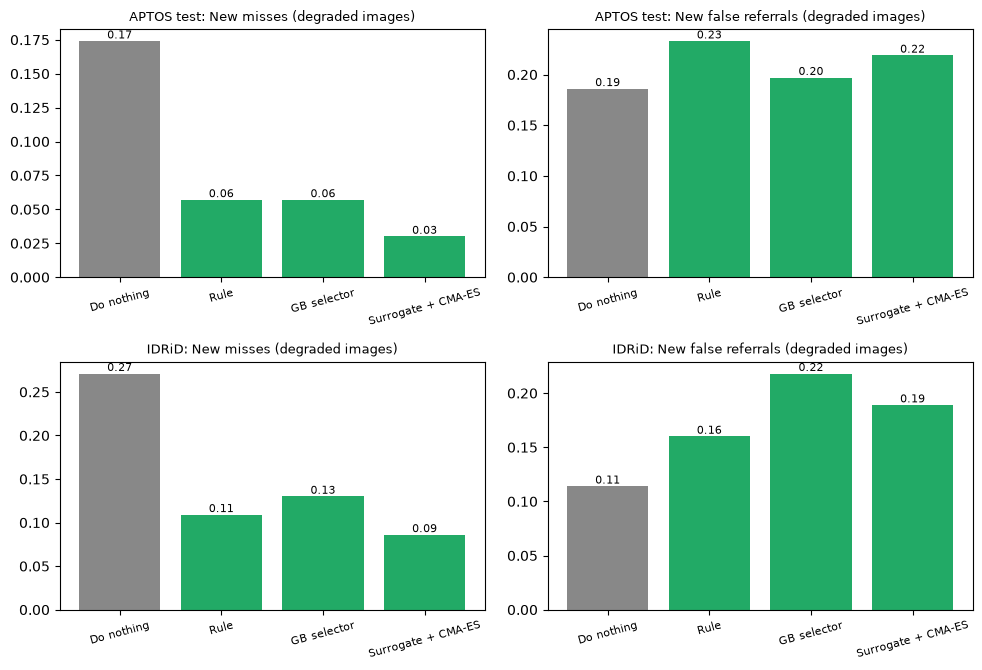

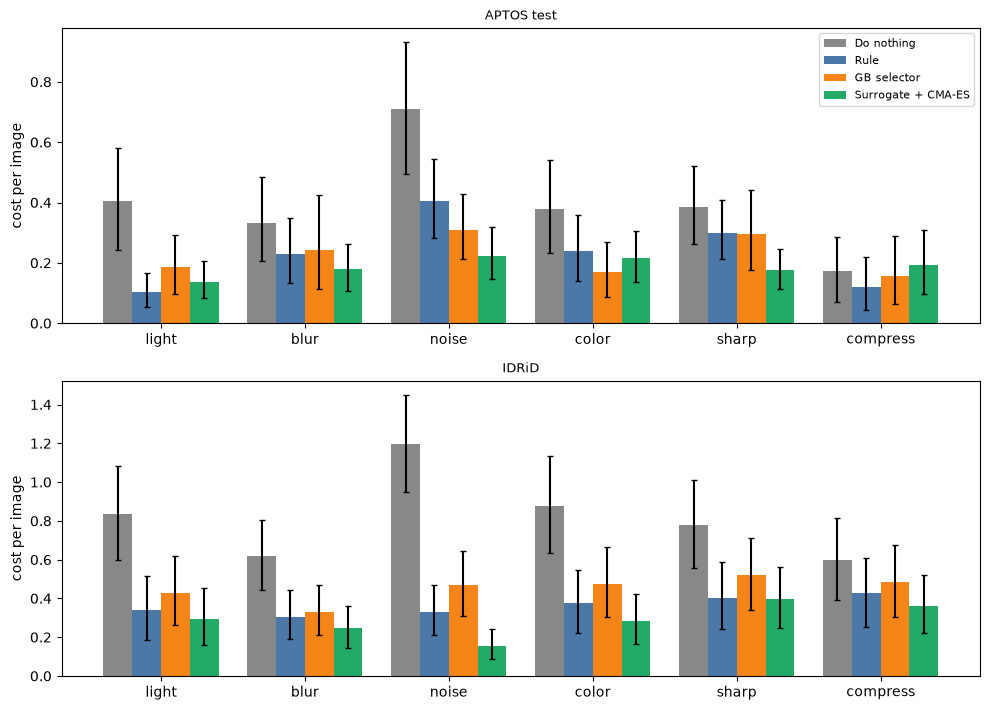

       set             policy   n  cost_without  cost_with  saved  saved_lo  saved_hi
APTOS test               Rule 733         0.385      0.229  0.156     0.089     0.233
APTOS test        GB selector 733         0.385      0.207  0.177     0.097     0.266
APTOS test Surrogate + CMA-ES 733         0.385      0.180  0.205     0.123     0.298
     IDRiD               Rule 954         0.713      0.324  0.389     0.286     0.497
     IDRiD        GB selector 954         0.713      0.395  0.318     0.209     0.432
     IDRiD Surrogate + CMA-ES 954         0.713      0.276  0.437     0.316     0.563


In [41]:
# FINAL RESULTS REPORT: per-set tables (missed / rescued / new misses, false referrals, cost with paired cluster-bootstrap CI) and two figures.
# Needs PSf / meta_ft from the final-test cell. Writes save/final_results_table.csv and save/figures/final_fig*.png.
import matplotlib.pyplot as plt
FIG = SAVE / 'figures'; FIG.mkdir(exist_ok=True)
def paired_ci_cluster(a, b, ids, n_boot=2000, seed=0):
    d = a - b; u, inv = np.unique(ids, return_inverse=True)
    sums, cnt = np.bincount(inv, weights=d), np.bincount(inv); r = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        pick = r.integers(0, len(u), len(u)); bs.append(sums[pick].sum() / cnt[pick].sum())
    return d.mean(), np.percentile(bs, [2.5, 97.5])

def make_report(meta, PSd, subsets, tag, pols=('Rule', 'GB selector', 'Surrogate + CMA-ES')):
    is_miss, is_fref = (lambda c: np.isclose(c, CM)), (lambda c: np.isclose(c, CF))
    none_c = PSd['Do nothing']; deg = (meta.kind == 'degraded').values; ids = meta.id.values
    caught = ((meta.label == 1) & (meta.p_clean >= thr)).values; cleared = ((meta.label == 0) & (meta.p_clean < thr)).values; out = []
    for sname, sm in subsets.items():
        for pol in pols:
            c = PSd[pol]
            for g, gm in [('degraded', deg), ('clean', ~deg)]:
                mk = sm & gm; n_c, n_h = max(caught[mk].sum(), 1), max(cleared[mk].sum(), 1)
                d, ci = paired_ci_cluster(none_c[mk], c[mk], ids[mk])
                out.append(dict(set=sname, policy=pol, group=g, n=int(mk.sum()), missed_without=int(is_miss(none_c)[mk].sum()),
                                rescued=int((is_miss(none_c) & ~is_miss(c))[mk].sum()), new_misses_caused=int((~is_miss(none_c) & is_miss(c))[mk].sum()),
                                newmiss_without=is_miss(none_c)[mk].sum() / n_c, newmiss_with=is_miss(c)[mk].sum() / n_c,
                                frefs_without=int(is_fref(none_c)[mk].sum()), avoided=int((is_fref(none_c) & ~is_fref(c))[mk].sum()),
                                new_frefs_caused=int((~is_fref(none_c) & is_fref(c))[mk].sum()),
                                newfref_without=is_fref(none_c)[mk].sum() / n_h, newfref_with=is_fref(c)[mk].sum() / n_h,
                                cost_without=none_c[mk].mean(), cost_with=c[mk].mean(), saved=d, saved_lo=ci[0], saved_hi=ci[1]))
    tab = pd.DataFrame(out).round(3); tab.to_csv(SAVE / f'{tag}_results_table.csv', index=False); display(tab)
    fig, ax = plt.subplots(len(subsets), 2, figsize=(10, 3.4 * len(subsets)), squeeze=False); labels = ['Do nothing'] + list(pols)
    for r_, sname in enumerate(subsets):
        t = tab[(tab.set == sname) & (tab.group == 'degraded')].set_index('policy')
        for c_, (kw, kw_, title) in enumerate([('newmiss_without', 'newmiss_with', 'New misses'), ('newfref_without', 'newfref_with', 'New false referrals')]):
            vals = [t[kw].iloc[0]] + [t.loc[p, kw_] for p in pols]
            ax[r_, c_].bar(range(len(vals)), vals, color=['#888'] + ['#2a6'] * len(pols)); ax[r_, c_].set_xticks(range(len(vals))); ax[r_, c_].set_xticklabels(labels, rotation=15, fontsize=8)
            ax[r_, c_].set_title(f'{sname}: {title} (degraded images)', fontsize=9)
            for i, v in enumerate(vals): ax[r_, c_].text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=8)
    plt.tight_layout(); plt.savefig(FIG / f'{tag}_fig1_newmiss_newfref.png', dpi=200); plt.show()
    fams = [f for f in dr_rl.FAMILIES if (meta.families.map(lambda s: f in s) & pd.Series(deg)).sum() > 0]; w = 0.2
    fig, ax = plt.subplots(len(subsets), 1, figsize=(10, 3.6 * len(subsets)), squeeze=False)
    for r_, (sname, sm) in enumerate(subsets.items()):
        for k, lab in enumerate(['Do nothing'] + list(pols)):
            m_, e_ = [], []
            for f in fams:
                mk = (meta.families.map(lambda s: f in s) & pd.Series(deg)).values & sm
                mu, ci = paired_ci_cluster(PSd[lab][mk], np.zeros(mk.sum()), ids[mk]); m_.append(mu); e_.append([mu - ci[0], ci[1] - mu])
            ax[r_, 0].bar(np.arange(len(fams)) + (k - 1.5) * w, m_, w, yerr=np.array(e_).T, capsize=2, label=lab, color=['#888', '#4c78a8', '#f58518', '#2a6'][k])
        ax[r_, 0].set_xticks(range(len(fams))); ax[r_, 0].set_xticklabels(fams); ax[r_, 0].set_ylabel('cost per image'); ax[r_, 0].set_title(sname, fontsize=9)
    ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / f'{tag}_fig2_cost_by_family.png', dpi=200); plt.show()
    return tab

subsets_ft = {'APTOS test': (meta_ft.dataset == 'aptos').values, 'IDRiD': (meta_ft.dataset == 'idrid').values}
tab_final = make_report(meta_ft, PSf, subsets_ft, 'final')
print(tab_final[tab_final.group == 'degraded'][['set', 'policy', 'n', 'cost_without', 'cost_with', 'saved', 'saved_lo', 'saved_hi']].to_string(index=False))


In [42]:
# Per-image latency of each policy component (one CPU core).
def tm(f, k=30):
    t = time.time(); [f(i) for i in range(k)]; return (time.time() - t) / k
p = plan_te[:30]; imgs_ = [read512(q['path']) for q in p]; st30 = np.c_[Dte['state'][:30], Dte['p0'][:30]]; Fm = fit_for(None)
t_feat = tm(lambda i: dr_rl.state_features(imgs_[i]))
t_rule = tm(lambda i: rule_choice(st30[i:i + 1]))
t_sel = tm(lambda i: [mdl.predict(st30[i:i + 1]) for mdl in Fm['selector']])
t_cma = tm(lambda i: cma_search(st30[i], Fm['surrogate'], i))
t_den = tm(lambda i: dr_rl.restore(imgs_[i], [0, 0, 0.75, 0])); t_gam = tm(lambda i: dr_rl.restore(imgs_[i], [1, 0, 0, 0])); t_deh = tm(lambda i: dr_rl.restore(imgs_[i], [0, 1, 0, 0]))
t_cls = tm(lambda i: classify_list([imgs_[i]]))
print(f'per image, one core: features {t_feat*1e3:.0f} ms | rule decision {t_rule*1e3:.1f} ms | GB selector decision {t_sel*1e3:.0f} ms | CMA-ES search {t_cma*1e3:.0f} ms')
print(f'restoration: gamma {t_gam*1e3:.0f} ms | dehaze {t_deh*1e3:.0f} ms | denoise (NLM) {t_den*1e3:.0f} ms | classifier (one image) {t_cls*1e3:.0f} ms')
print(f'rule/selector: about {(t_feat + t_den + t_cls)*1e3:.0f} ms worst case; CMA-ES: about {(t_feat + t_cma + t_den + t_cls)*1e3:.0f} ms; '
      f'feedback selector (5 restorations + 5 classifier runs): about {(t_feat + t_gam + t_deh + 3*t_den + 5*t_cls)*1e3:.0f} ms')

per image, one core: features 31 ms | rule decision 0.0 ms | GB selector decision 48 ms | CMA-ES search 441 ms
restoration: gamma 36 ms | dehaze 54 ms | denoise (NLM) 95 ms | classifier (one image) 163 ms
rule/selector: about 288 ms worst case; CMA-ES: about 729 ms; feedback selector (5 restorations + 5 classifier runs): about 1218 ms


trained with 500 samples
trained with 1000 samples
trained with 2000 samples
trained with 3000 samples


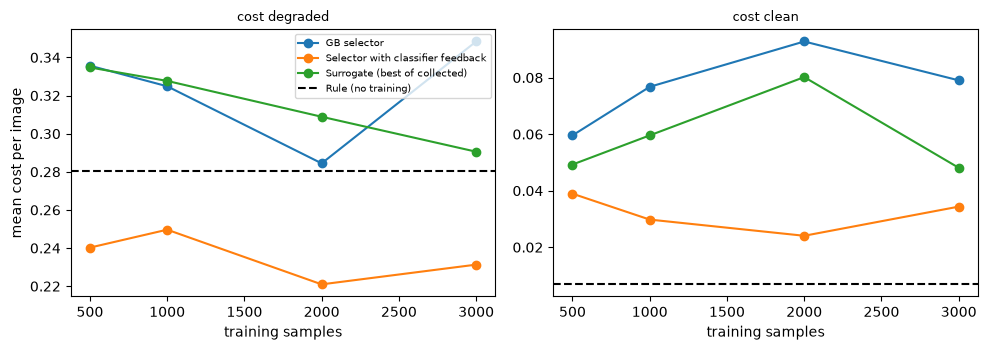

,policy,n_train,rep,cost_degraded,cost_clean
0,GB selector,500,1.0,0.336,0.060
1,GB selector,1000,1.0,0.325,0.077
2,GB selector,2000,1.0,0.284,0.093
3,GB selector,3000,0.0,0.348,0.079
4,Selector with classifier feedback,500,1.0,0.240,0.039
5,Selector with classifier feedback,1000,1.0,0.250,0.030
6,Selector with classifier feedback,2000,1.0,0.221,0.024
7,Selector with classifier feedback,3000,0.0,0.231,0.034
8,Surrogate (best of collected),500,1.0,0.335,0.049
9,Surrogate (best of collected),1000,1.0,0.328,0.060


In [43]:
# Learning curve: cost vs number of training samples for selector / feedback selector / surrogate.
sizes, reps = [500, 1000, 2000, len(meta_tr)], 3
st_te, X_te, cost_te, _, _ = rows(Dte, meta_te, np.arange(len(meta_te))); ar_te = np.arange(len(cost_te)); deg_te = (meta_te.kind == 'degraded').values
rule_cost = cost_te[ar_te, rule_choice(st_te)]
curve = []
for ns_ in sizes:
    for rep in range(reps if ns_ < len(meta_tr) else 1):
        idx = np.random.default_rng(100 + rep).choice(len(meta_tr), ns_, replace=False)
        st, X, cost, _, _ = rows(Dtr, meta_tr, idx)
        selm = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30, random_state=c).fit(st, cost[:, c]) for c in range(6)]
        fbm_ = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30, random_state=c).fit(fb_X(Dtr, idx), cost[:, c]) for c in range(6)]
        sur = ens_pred(fit_ens(X.reshape(-1, X.shape[-1]), cost.reshape(-1), k=2))
        ps_ = np.stack([mm.predict(st_te) for mm in selm], 1); pick = np.where(ps_.min(1) + TOL < ps_[:, 0], ps_.argmin(1), 0)
        pf_ = np.stack([mm.predict(fb_X(Dte, np.arange(len(meta_te)))) for mm in fbm_], 1); pickf = np.where(pf_.min(1) + TOL < pf_[:, 0], pf_.argmin(1), 0)
        mu, _ = sur(X_te.reshape(-1, X_te.shape[-1])); picks = mu.reshape(-1, 10).argmin(1)
        for name, ch in [('GB selector', cost_te[ar_te, pick]), ('Selector with classifier feedback', cost_te[ar_te, pickf]), ('Surrogate (best of collected)', cost_te[ar_te, picks])]:
            curve.append(dict(n_train=ns_, rep=rep, policy=name, cost_degraded=ch[deg_te].mean(), cost_clean=ch[~deg_te].mean()))
    print('trained with', ns_, 'samples', flush=True)
cv = pd.DataFrame(curve).groupby(['policy', 'n_train']).mean(numeric_only=True).reset_index(); cv.to_csv(SAVE / 'learning_curve.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for j, col in enumerate(['cost_degraded', 'cost_clean']):
    for pol, g in cv.groupby('policy'): ax[j].plot(g.n_train, g[col], marker='o', label=pol)
    ax[j].axhline(rule_cost[deg_te].mean() if j == 0 else rule_cost[~deg_te].mean(), color='k', ls='--', label='Rule (no training)'); ax[j].set_xlabel('training samples'); ax[j].set_title(col.replace('_', ' '), fontsize=9)
ax[0].set_ylabel('mean cost per image'); ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / 'learning_curve.png', dpi=200); plt.show(); display(cv.round(3))

## Export for the inference script
Saves the policy models, locked classifier, colour reference and demo images that `infer.py` needs. Run once after the final test.


In [ ]:
# ===== EXPORT FOR infer.py: run ONCE after the final-test cells (needs Dtr/meta_tr, thr, imgs, tr_i from above) =====
# Writes everything the standalone inference script needs to ROOT/export_weights, plus demo images to ROOT/sample_data.
import joblib, shutil
LAM, TOL = 0.5, 0.05                    # frozen policy settings (same values as the final test); defined here so the CMA cells need not be re-run
from sklearn.ensemble import HistGradientBoostingRegressor
EXPORT = ROOT / 'export_weights'; EXPORT.mkdir(exist_ok=True)

# 1) gate thresholds for the RULE policy: 1% / 99% quantiles of the 12 statistics on CLEAN calibration images
#    (recomputed here because `lo`/`hi`/`cal`/`F_cal` are redefined by earlier cells)
cal_x = imgs.loc[tr_i].sample(min(300, len(tr_i)), random_state=0)
F_cal_x = np.stack([dr_rl.state_features(read512(p)) for p in cal_x.path512])
lo_x, hi_x = np.quantile(F_cal_x, 0.01, axis=0), np.quantile(F_cal_x, 0.99, axis=0)

# 2) refit the policy models on ALL collected training samples (identical to fit_for(None); seeded -> same models as the final test)
st_x, X_x, cost_x, _, _ = rows(Dtr, meta_tr, np.arange(len(meta_tr)))
surrogate_x = fit_ens(X_x.reshape(-1, X_x.shape[-1]), cost_x.reshape(-1))            # 3 HGB regressors: [state, action] -> cost
selector_x = [HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, min_samples_leaf=30,
                                            random_state=c).fit(st_x, cost_x[:, c]) for c in range(6)]   # state -> cost per pipeline
joblib.dump(dict(lo=lo_x, hi=hi_x, surrogate=surrogate_x, selector=selector_x, TOL=TOL, LAM=LAM,
                 feature_names=dr_rl.FEATURE_NAMES + ['p0'], threshold=float(thr)), EXPORT / 'policy.joblib')

# 3) locked classifier + colour reference
for f in ('locked_model.pt', 'locked_model.json', 'ref_cdf.npy'): shutil.copy(SAVE / f, EXPORT / f)

# 4) demo images (policy-split images the classifier never trained on): 2 clean + degradations that flip a correct 'referable' call
from infer import DEMO_DEGRADATIONS                      # infer.py must sit next to this notebook
SAMPLE = ROOT / 'sample_data'; SAMPLE.mkdir(exist_ok=True); JQ = [cv2.IMWRITE_JPEG_QUALITY, 95]
for lbl, tag in ((1, 'referable'), (0, 'healthy')):
    r = imgs[(imgs.label == lbl) & ((imgs.p_clean >= thr) == bool(lbl))].iloc[0]       # correctly classified when clean
    cv2.imwrite(str(SAMPLE / f'clean_{tag}_{r.id}.jpg'), cv2.imread(r.path512), JQ)
cands = imgs[(imgs.label == 1) & (imgs.p_clean >= thr)].sample(60, random_state=0)
for dname, spec in DEMO_DEGRADATIONS.items():
    for _, r in cands.iterrows():
        x = read512(r.path512); g = np.random.default_rng(0)
        for n_, kw in spec: x = dr_ops.DEG[n_](x, g, **kw)
        x = dr_rl.to512(x)
        if classify_list([x])[0] < thr:                  # degradation causes a NEW MISS -> good demonstration case
            cv2.imwrite(str(SAMPLE / f'{dname}_{r.id}.jpg'), cv2.cvtColor(x, cv2.COLOR_RGB2BGR), JQ); break
print(sorted(p.name for p in EXPORT.iterdir()), '\n', sorted(p.name for p in SAMPLE.iterdir()))
# Then copy ROOT/export_weights/* -> submission/weights/ and ROOT/sample_data/* -> submission/sample_data/
